# Análise de rotatividade e retenção de clientes — Model Fitness

## Contexto e objetivo

A Model Fitness busca desenvolver uma estratégia de retenção baseada em dados. Esta análise investiga a relação entre a rotatividade e as características dos clientes, seus contratos, frequência de visitas e gastos em serviços adicionais.

O objetivo é prever a saída de clientes no mês seguinte, identificar grupos com perfis semelhantes e propor ações de retenção com base nos resultados.

## Dados

O conjunto contém informações sobre os clientes e seu relacionamento com a academia. A variável alvo é `Churn`: **1** indica saída e **0** indica permanência no período analisado.

## 1. Carregamento dos dados

Serão importadas as bibliotecas necessárias e carregado o conjunto de dados da Model Fitness. A inspeção inicial permitirá verificar o tamanho da base, os nomes das colunas e os primeiros registros.

In [1]:
import pandas as pd

# Paletas utilizadas ao longo do projeto
CORES = {
    'texto': '#2D3748',
    'fundo': '#F8F9FA',
    'grade': '#E2E8F0',
    'azul_escuro': '#263B50',
    'referencia': '#4A5568'
}

churn_colors = {
    'Permaneceram': '#596644',
    'Saíram': '#7A3038'
}

cores_modelos = {
    'Regressão logística': churn_colors['Saíram'],
    'Floresta aleatória': churn_colors['Permaneceram']
}

cluster_colors = {
    'Grupo 0': '#7A3038',
    'Grupo 1': '#596644',
    'Grupo 2': '#263B50',
    'Grupo 3': '#B38A35',
    'Grupo 4': '#BC7055'
}

cluster_order = list(cluster_colors.keys())


def formatar_tabela(tabela, formatos=None, casas=2):
    """Aplica o estilo e o formato numérico sem alterar os dados."""

    def numero_br(valor):
        return (
            f'{valor:,.{casas}f}'
            .replace(',', 'X')
            .replace('.', ',')
            .replace('X', '.')
        )

    formatos_padrao = {
        coluna: (
            '{:.0f}'
            if pd.api.types.is_integer_dtype(tabela[coluna])
            else numero_br
        )
        for coluna in tabela.select_dtypes(include='number').columns
    }

    if formatos is not None:
        formatos_padrao.update(formatos)

    return (
        tabela.style
        .format(formatos_padrao, na_rep='—')
        .set_table_styles([
            {
                'selector': 'th',
                'props': [
                    ('background-color', churn_colors['Saíram'] + ' !important'),
                    ('color', '#FFFFFF !important'),
                    ('text-align', 'right !important'),
                    ('padding', '10px')
                ]
            },
            {
                'selector': 'td',
                'props': [
                    ('background-color', CORES['fundo'] + ' !important'),
                    ('color', CORES['texto'] + ' !important'),
                    ('text-align', 'right !important'),
                    ('padding', '10px'),
                    ('border-bottom', f"1px solid {CORES['grade']}")
                ]
            }
        ])
    )


# Carregar os dados da Model Fitness
gym = pd.read_csv('data/gym_churn_us.csv')

# Exibir o tamanho da base e os nomes das colunas
print(f'Quantidade de clientes: {gym.shape[0]}')
print(f'Quantidade de colunas: {gym.shape[1]}')
print('\nColunas da base:')
print(gym.columns.tolist())

# Exibir os primeiros cinco registros com o padrão definido
display(formatar_tabela(gym.head()))

Quantidade de clientes: 4000
Quantidade de colunas: 14

Colunas da base:
['gender', 'Near_Location', 'Partner', 'Promo_friends', 'Phone', 'Contract_period', 'Group_visits', 'Age', 'Avg_additional_charges_total', 'Month_to_end_contract', 'Lifetime', 'Avg_class_frequency_total', 'Avg_class_frequency_current_month', 'Churn']


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,"14,23","5,00",3,"0,02","0,00",0
1,0,1,0,0,1,12,1,31,"113,20","12,00",7,"1,92","1,91",0
2,0,1,1,0,1,1,0,28,"129,45","1,00",2,"1,86","1,74",0
3,0,1,1,1,1,12,1,33,"62,67","12,00",2,"3,21","3,36",0
4,1,1,1,1,1,1,0,26,"198,36","1,00",3,"1,11","1,12",0


## 2. Análise exploratória dos dados

A base contém 4.000 registros e 14 colunas, incluindo a variável alvo `Churn`. Serão verificados os tipos de dados, valores ausentes, registros duplicados e estatísticas descritivas. Em seguida, serão comparadas as características dos clientes que saíram e dos que permaneceram.

In [2]:
# Verificar tipos e preenchimento das colunas
gym.info()

# Contar valores ausentes por coluna
print('\nValores ausentes por coluna:')
print(gym.isna().sum())

# Verificar registros completamente duplicados
print(f'\nRegistros duplicados: {gym.duplicated().sum()}')

# Exibir as estatísticas descritivas com o padrão definido
display(formatar_tabela(gym.describe()))

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
count,"4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00","4.000,00"
mean,"0,51","0,85","0,49","0,31","0,90","4,68","0,41","29,18","146,94","4,32","3,72","1,88","1,77","0,27"
std,"0,50","0,36","0,50","0,46","0,30","4,55","0,49","3,26","96,36","4,19","3,75","0,97","1,05","0,44"
min,"0,00","0,00","0,00","0,00","0,00","1,00","0,00","18,00","0,15","1,00","0,00","0,00","0,00","0,00"
25%,"0,00","1,00","0,00","0,00","1,00","1,00","0,00","27,00","68,87","1,00","1,00","1,18","0,96","0,00"
50%,"1,00","1,00","0,00","0,00","1,00","1,00","0,00","29,00","136,22","1,00","3,00","1,83","1,72","0,00"
75%,"1,00","1,00","1,00","1,00","1,00","6,00","1,00","31,00","210,95","6,00","5,00","2,54","2,51","1,00"
max,"1,00","1,00","1,00","1,00","1,00","12,00","1,00","41,00","552,59","12,00","31,00","6,02","6,15","1,00"


### Qualidade dos dados e perfil inicial

A base possui 4.000 registros, sem valores ausentes ou linhas completamente duplicadas. Não há necessidade de preenchimento ou remoção de registros por esses motivos.

A idade média dos clientes é de 29,18 anos, com desvio padrão de 3,26 anos. O tempo médio de relacionamento com a academia é de 3,72 meses, e a frequência média histórica é de 1,88 visita por semana.

A mediana da duração dos contratos é de um mês, indicando uma concentração em planos curtos. Aproximadamente 27% dos clientes apresentam rotatividade no período analisado.

As características possuem escalas diferentes, o que será considerado na preparação dos dados para a regressão logística e o agrupamento.

Os valores mínimos e máximos não apresentam inconsistências evidentes nesta inspeção. As variáveis binárias estão no intervalo de 0 a 1, e os limites de idade, duração dos contratos e frequência de visitas são plausíveis. As distribuições serão examinadas para avaliar possíveis valores atípicos.

### 2.1. Comparação entre clientes que permaneceram e saíram

Serão comparadas as médias das características por situação de rotatividade. Nas variáveis binárias, a média representa a proporção de clientes com valor 1 em cada grupo. Essa comparação ajudará a identificar diferenças de perfil associadas à saída.

In [3]:
# Comparar as médias por situação de rotatividade
churn_profile = gym.groupby('Churn').mean().T

# Identificar os grupos
churn_profile.columns = ['Permaneceram (0)', 'Saíram (1)']

# Exibir com o padrão definido
display(formatar_tabela(churn_profile))

,Permaneceram (0),Saíram (1)
gender,"0,51","0,51"
Near_Location,"0,87","0,77"
Partner,"0,53","0,36"
Promo_friends,"0,35","0,18"
Phone,"0,90","0,90"
Contract_period,"5,75","1,73"
Group_visits,"0,46","0,27"
Age,"29,98","26,99"
Avg_additional_charges_total,"158,45","115,08"
Month_to_end_contract,"5,28","1,66"


Os clientes que saíram têm, em média, menos tempo de relacionamento, contratos mais curtos e menor frequência de visitas, especialmente no mês corrente. Também apresentam menor participação em atividades coletivas e menores gastos adicionais.

Gênero e fornecimento de telefone não mostram diferenças relevantes nas médias dos grupos.

Esses resultados sugerem atenção aos primeiros meses de relacionamento e à baixa frequência. As diferenças observadas indicam associações, sem comprovar as causas da rotatividade.

### 2.2. Distribuição das características por rotatividade

Serão comparadas as distribuições das características entre clientes que permaneceram e clientes que saíram. Os gráficos ajudarão a identificar concentrações, diferenças entre os perfis e possíveis valores atípicos.

O verde musgo representará os clientes que permaneceram, e o vermelho fechado, os que saíram. As proporções serão calculadas dentro de cada grupo para permitir a comparação entre grupos de tamanhos diferentes.

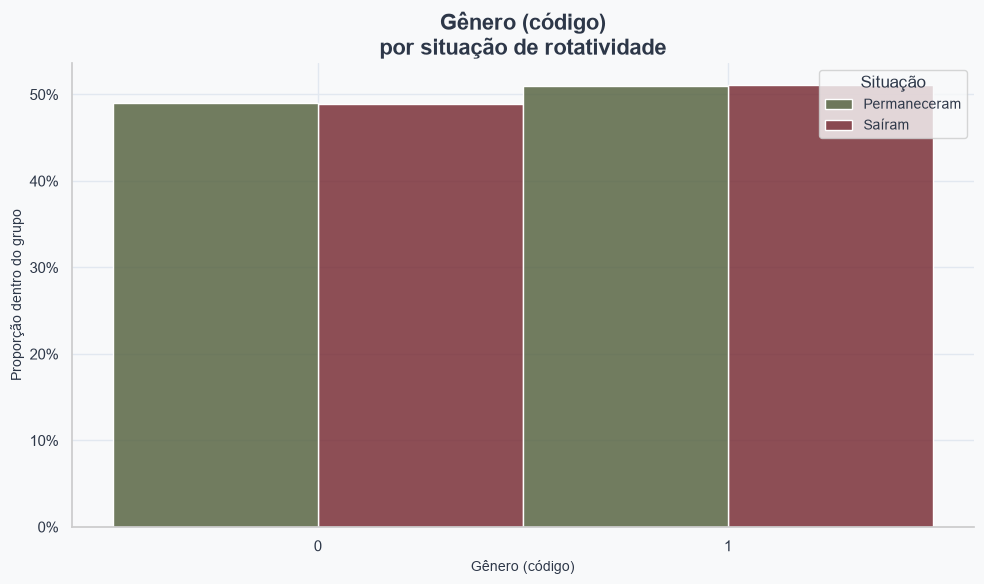

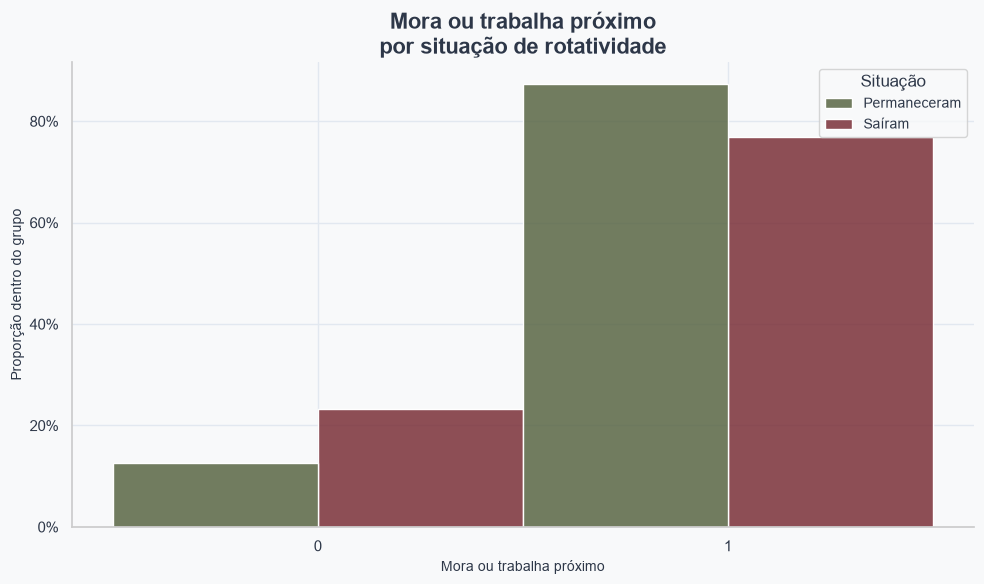

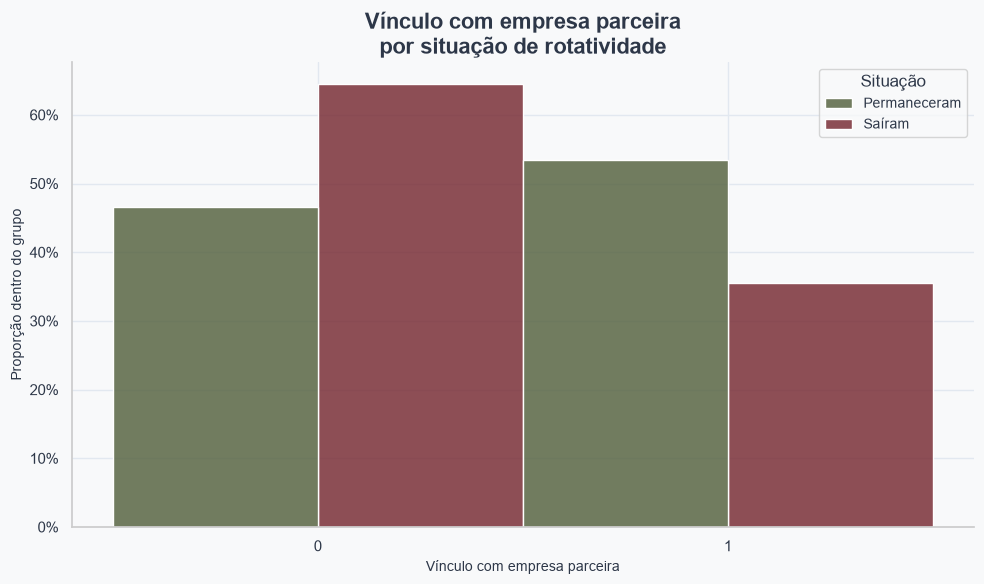

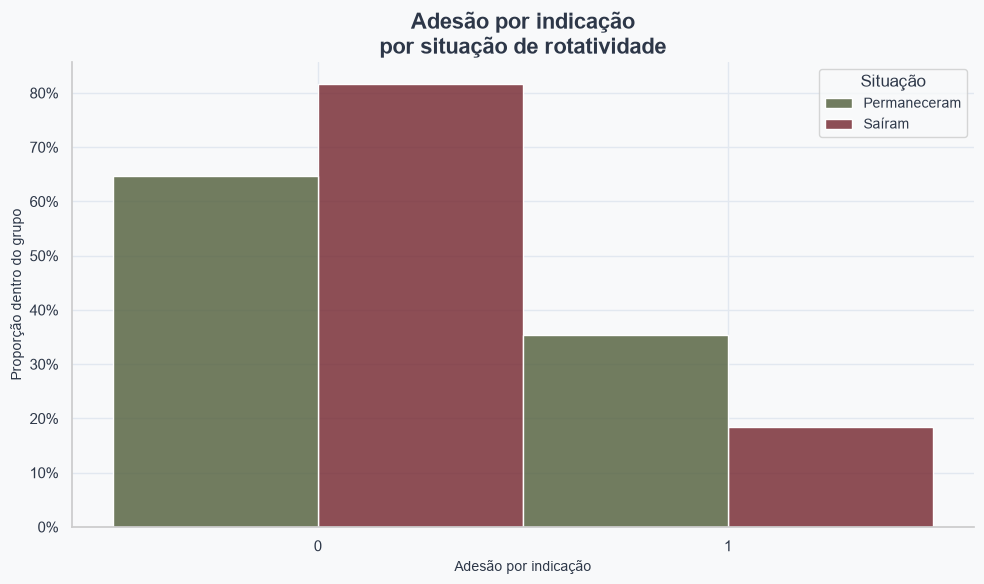

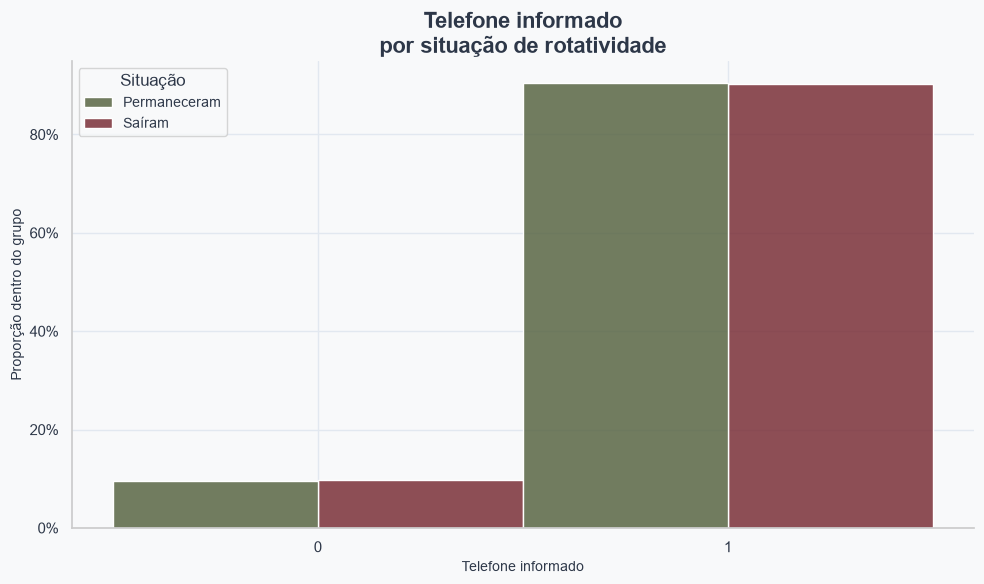

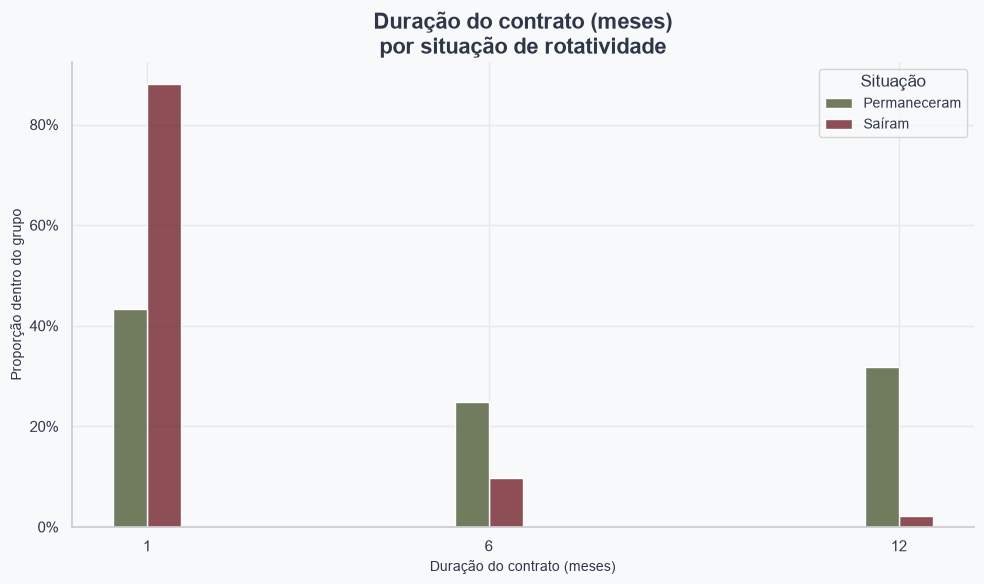

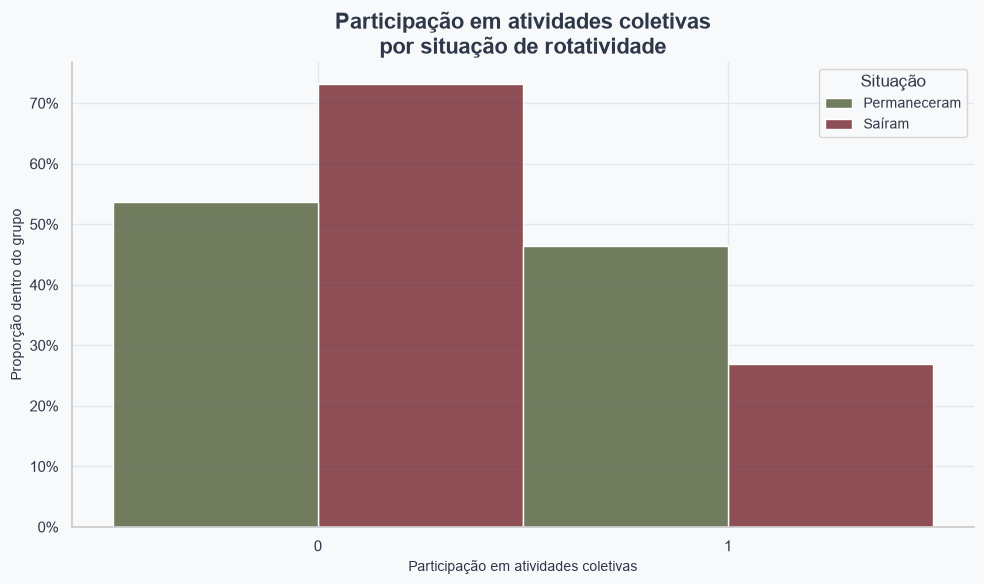

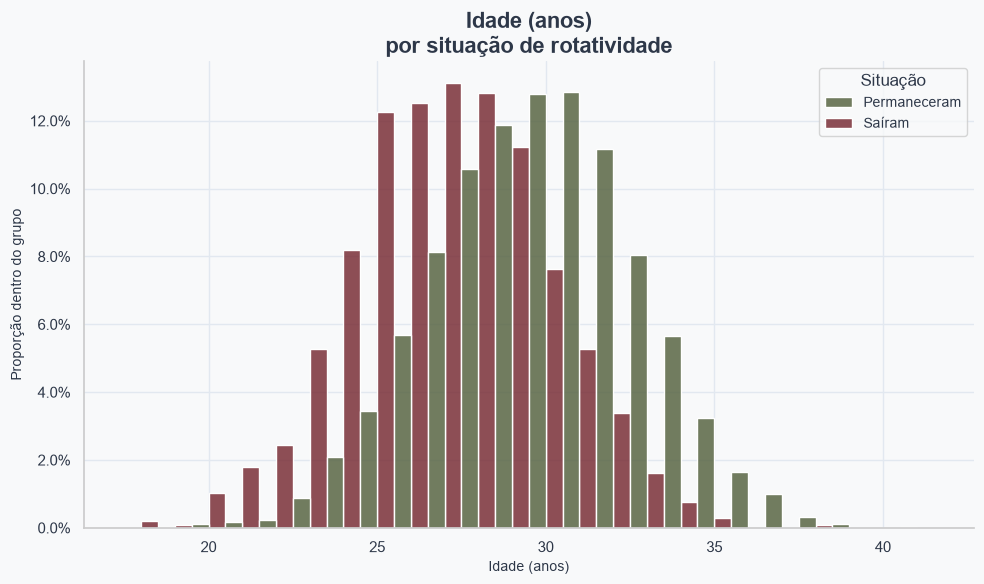

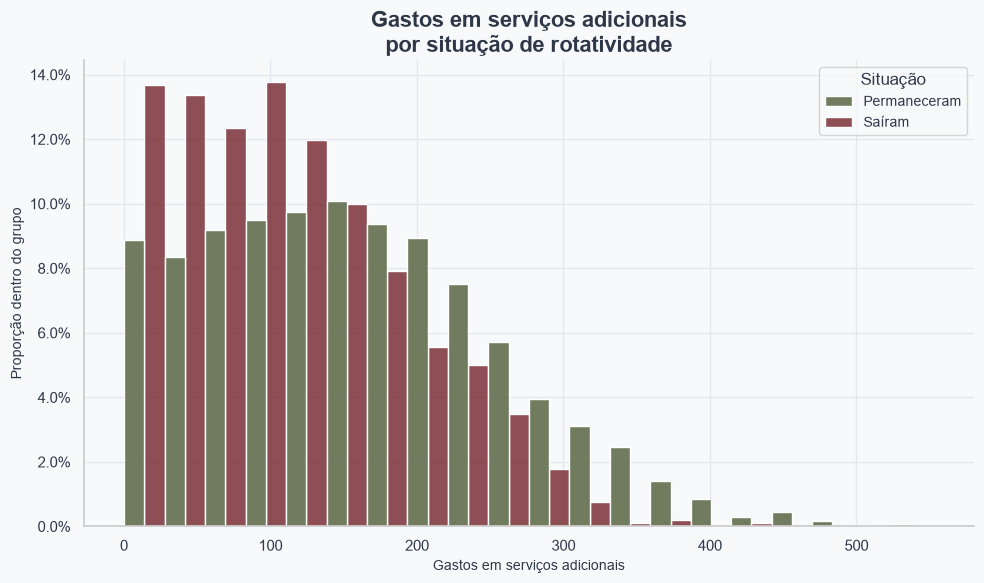

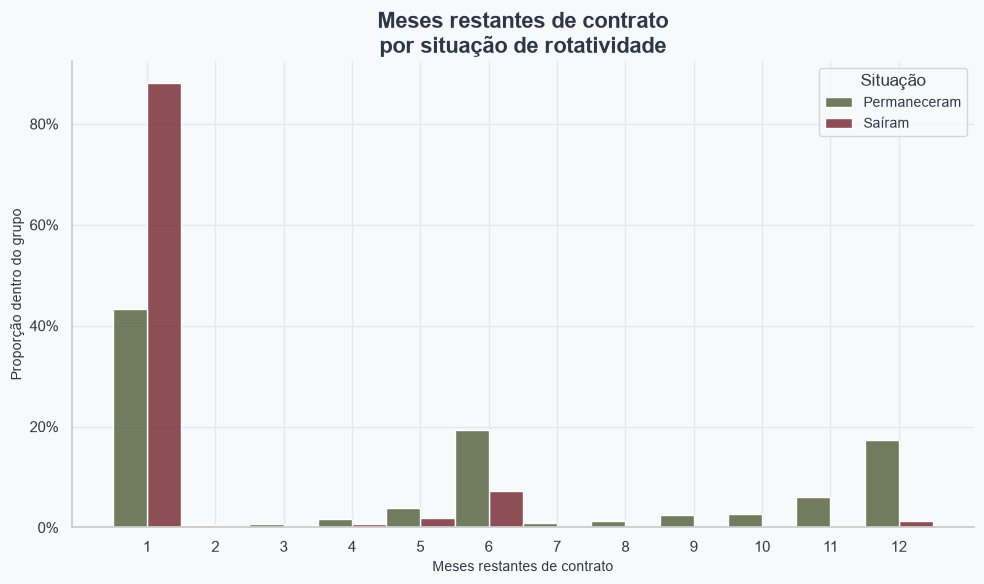

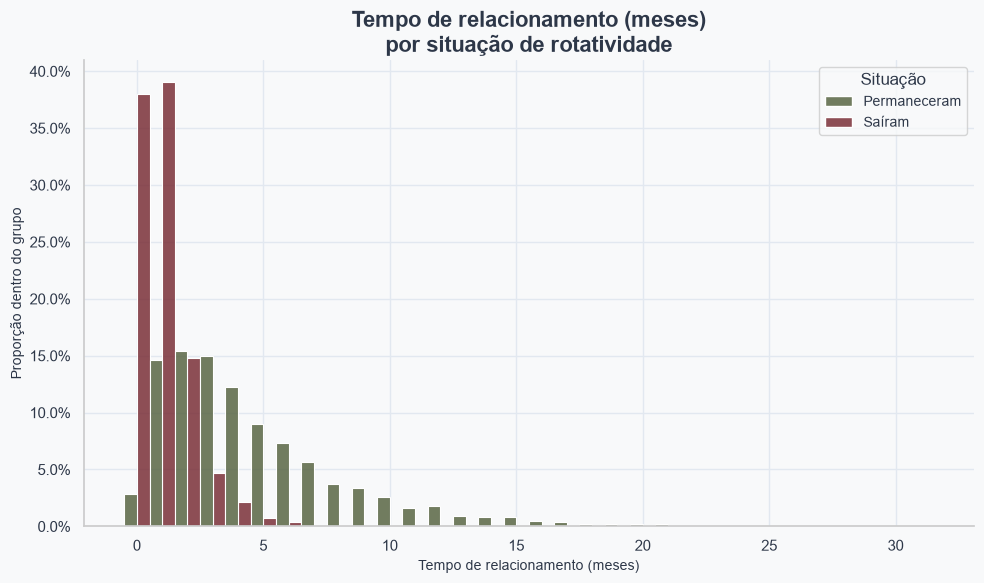

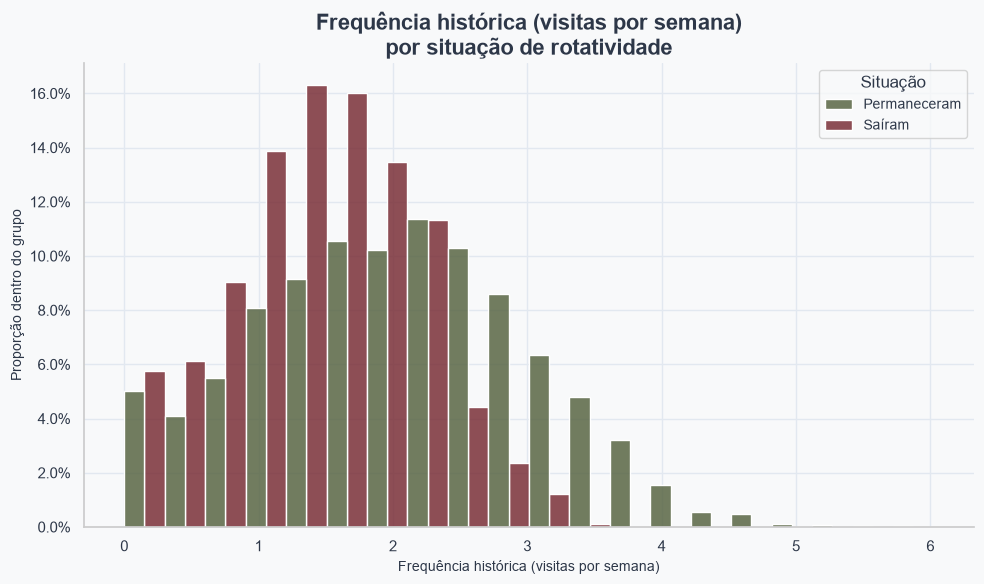

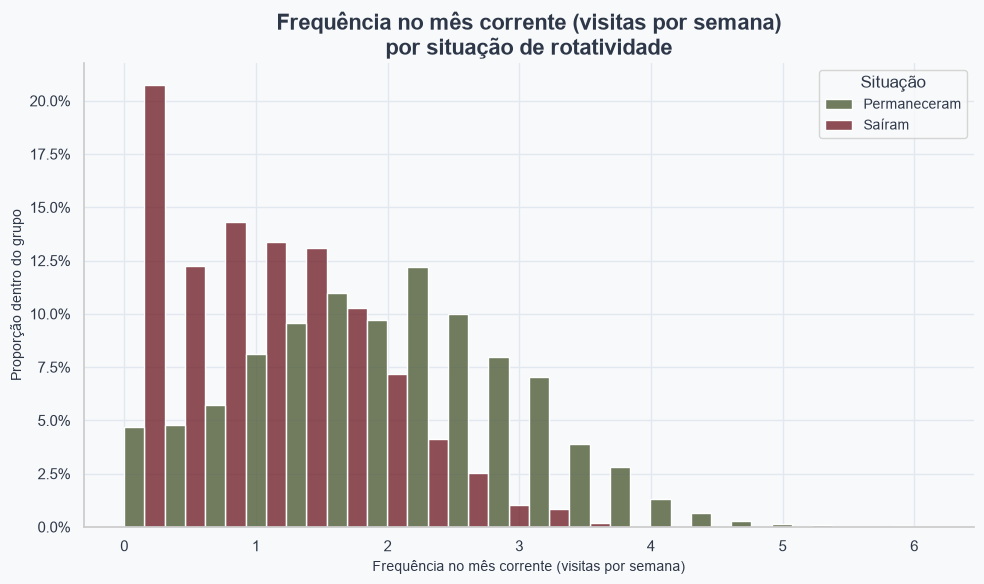

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Definir o padrão visual dos gráficos
sns.set_theme(
    style='whitegrid',
    rc={
        'axes.facecolor': CORES['fundo'],
        'figure.facecolor': CORES['fundo'],
        'axes.labelcolor': CORES['texto'],
        'text.color': CORES['texto'],
        'xtick.color': CORES['texto'],
        'ytick.color': CORES['texto'],
        'grid.color': CORES['grade'],
        'axes.titlesize': 16,
        'axes.titleweight': 'bold',
        'axes.labelsize': 10,
        'legend.fontsize': 10
    }
)

# Criar rótulos para os gráficos sem alterar a base original
plot_data = gym.copy()
plot_data['Situação'] = plot_data['Churn'].map({
    0: 'Permaneceram',
    1: 'Saíram'
})

# Definir os nomes das características em português
feature_labels = {
    'gender': 'Gênero (código)',
    'Near_Location': 'Mora ou trabalha próximo',
    'Partner': 'Vínculo com empresa parceira',
    'Promo_friends': 'Adesão por indicação',
    'Phone': 'Telefone informado',
    'Contract_period': 'Duração do contrato (meses)',
    'Group_visits': 'Participação em atividades coletivas',
    'Age': 'Idade (anos)',
    'Avg_additional_charges_total': 'Gastos em serviços adicionais',
    'Month_to_end_contract': 'Meses restantes de contrato',
    'Lifetime': 'Tempo de relacionamento (meses)',
    'Avg_class_frequency_total': 'Frequência histórica (visitas por semana)',
    'Avg_class_frequency_current_month': 'Frequência no mês corrente (visitas por semana)'
}

# Identificar características com valores discretos
discrete_features = [
    'gender', 'Near_Location', 'Partner', 'Promo_friends',
    'Phone', 'Contract_period', 'Group_visits',
    'Age', 'Month_to_end_contract', 'Lifetime'
]

# Comparar as distribuições com normalização separada por grupo
for feature, label in feature_labels.items():
    fig, ax = plt.subplots(figsize=(10, 6))

    hist_options = {'bins': 20}
    if feature in discrete_features:
        hist_options = {'discrete': True}

    sns.histplot(
        data=plot_data,
        x=feature,
        hue='Situação',
        hue_order=['Permaneceram', 'Saíram'],
        palette=churn_colors,
        stat='probability',
        common_norm=False,
        common_bins=True,
        multiple='dodge',
        alpha=0.85,
        ax=ax,
        **hist_options
    )

    ax.set_title(f'{label}\npor situação de rotatividade')
    ax.set_xlabel(label)
    ax.set_ylabel('Proporção dentro do grupo')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    if feature in discrete_features:
        values = sorted(gym[feature].unique())
        if len(values) <= 12:
            ax.set_xticks(values)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

As distribuições reforçam as diferenças observadas nas médias: clientes que saíram estão mais concentrados em contratos mensais, menor tempo de relacionamento e baixa frequência de visitas no mês corrente.

Entre os que permaneceram, há maior participação em atividades coletivas, adesão por indicação e vínculo com empresas parceiras. Gênero e fornecimento de telefone apresentam distribuições semelhantes nos dois grupos.

Os gráficos sugerem que tempo de relacionamento, contrato e frequência podem ajudar a identificar clientes com maior risco de saída. Essas associações serão examinadas na matriz de correlação e na modelagem.

### 2.3. Correlação entre as variáveis

A matriz de correlação permitirá identificar associações lineares entre as características e a rotatividade. Também serão observadas correlações fortes entre características, que podem dificultar a interpretação dos coeficientes da regressão logística.

Correlação não comprova causa e efeito.

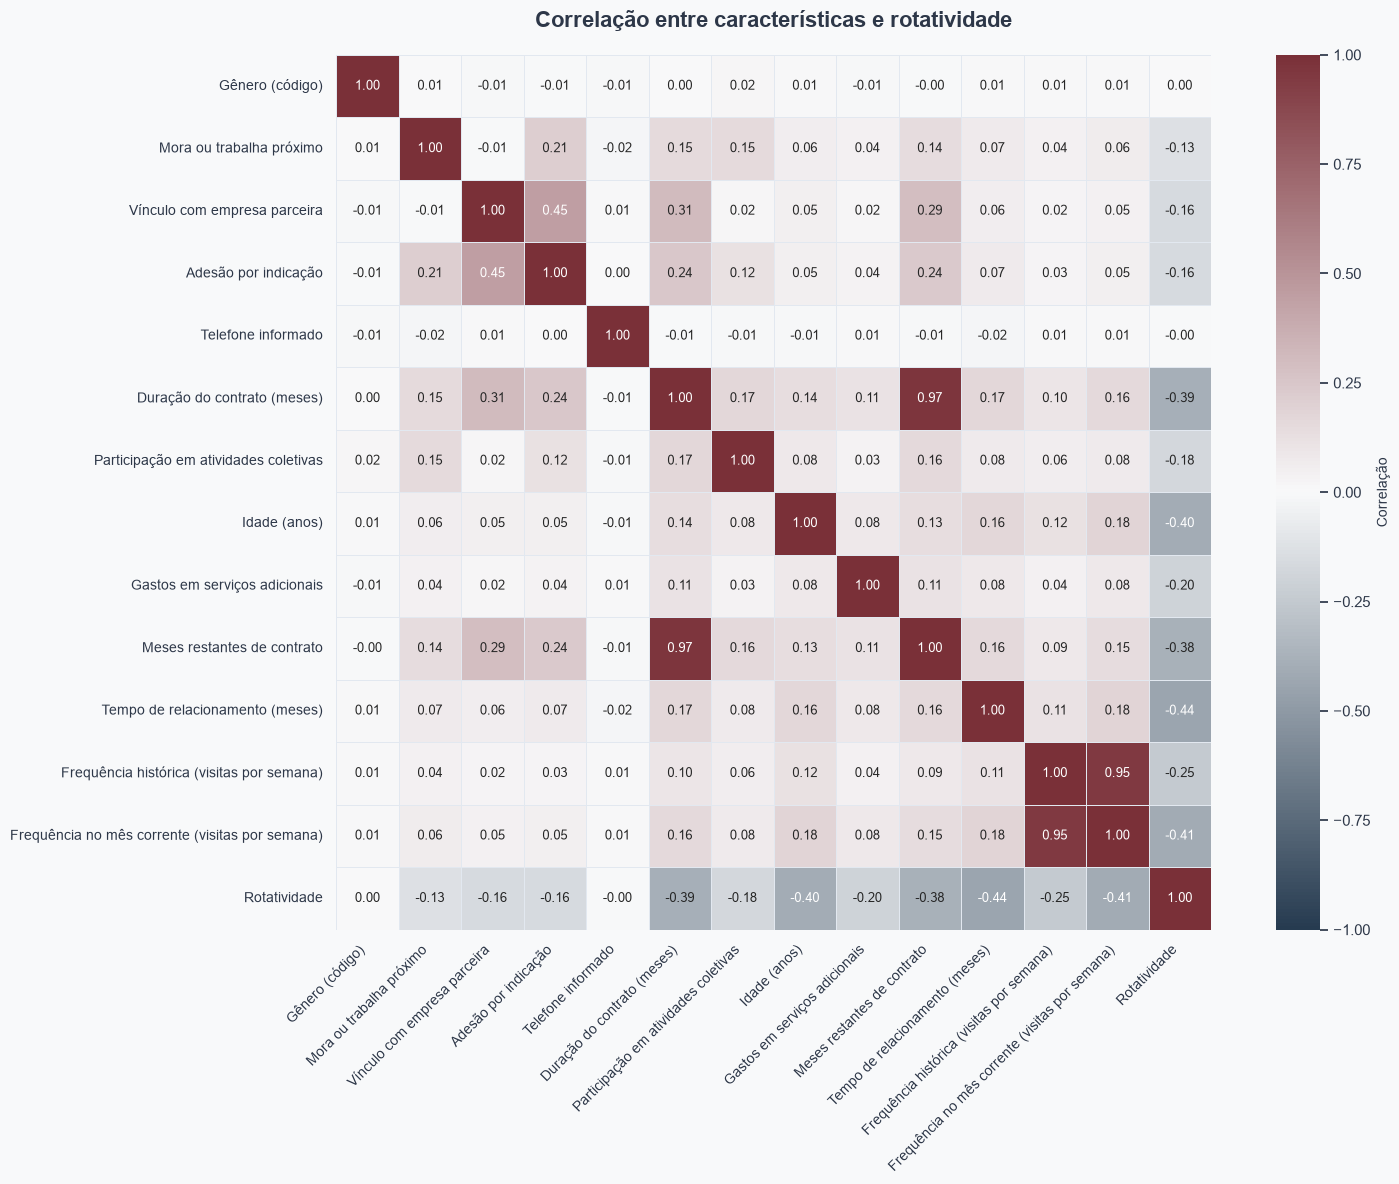

In [5]:
from matplotlib.colors import LinearSegmentedColormap

# Calcular a matriz de correlação
correlation_matrix = gym.corr()

# Reutilizar as cores centralizadas
correlation_colors = LinearSegmentedColormap.from_list(
    'correlacao_projeto',
    [CORES['azul_escuro'], CORES['fundo'], churn_colors['Saíram']]
)

# Exibir os nomes das características em português
correlation_labels = {
    **feature_labels,
    'Churn': 'Rotatividade'
}

correlation_plot = correlation_matrix.rename(
    index=correlation_labels,
    columns=correlation_labels
)

fig, ax = plt.subplots(figsize=(16, 12))

sns.heatmap(
    correlation_plot,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 9},
    cmap=correlation_colors,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor=CORES['grade'],
    cbar_kws={'label': 'Correlação'},
    ax=ax
)

ax.set_title('Correlação entre características e rotatividade', pad=20)
ax.tick_params(axis='both', labelsize=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

As associações negativas mais fortes com a rotatividade aparecem no tempo de relacionamento (−0,44), na frequência do mês corrente (−0,41), na idade (−0,40) e na duração do contrato (−0,39). Valores maiores nessas características estão associados a menor ocorrência de saída.

Há duas correlações fortes entre características: duração e meses restantes do contrato (0,97), e frequência histórica e frequência do mês corrente (0,95). Esses pares apresentam informações semelhantes, o que exige cuidado na interpretação dos coeficientes da regressão logística.

Gênero e fornecimento de telefone apresentam correlação próxima de zero com a rotatividade. Isso indica pouca associação linear isolada, mas não comprova ausência de utilidade para os modelos.

## 3. Predição da rotatividade de clientes

Serão treinados modelos de regressão logística e floresta aleatória para prever a saída de clientes. A comparação considerará acurácia, precisão e sensibilidade, com atenção à identificação dos clientes que saíram.

### 3.1. Preparação dos dados

Os dados serão divididos em 80% para treino e 20% para validação, preservando a proporção de rotatividade e usando `random_state=0`. A variável `Churn` será separada das características.

Os dois modelos utilizarão a mesma divisão. Na regressão logística, a padronização será ajustada apenas no treino e aplicada à validação. A floresta aleatória utilizará os dados na escala original.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separar as características e a variável alvo
X = gym.drop('Churn', axis=1)
y = gym['Churn']

# Dividir os dados preservando a proporção das classes
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Ajustar a padronização apenas nos dados de treino
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Conferir o tamanho dos conjuntos
print(f'Clientes no treino: {X_train.shape[0]}')
print(f'Clientes na validação: {X_valid.shape[0]}')

# Conferir a proporção de rotatividade em cada conjunto
class_distribution = pd.DataFrame({
    'Treino (%)': y_train.value_counts(normalize=True) * 100,
    'Validação (%)': y_valid.value_counts(normalize=True) * 100
}).sort_index()

display(formatar_tabela(class_distribution))

Clientes no treino: 3200
Clientes na validação: 800


,Treino (%),Validação (%)
Churn,,
0,"73,47","73,50"
1,"26,53","26,50"


A divisão preservou a proporção das classes: aproximadamente 26,5% dos clientes apresentam rotatividade em ambos os conjuntos. A padronização foi ajustada apenas no treino, evitando usar informações da validação nessa preparação.

### 3.2. Treinamento e avaliação dos modelos

A regressão logística será treinada com as características padronizadas, e a floresta aleatória, com os dados na escala original. Ambos os modelos gerarão classes previstas e probabilidades de saída para os clientes da validação.

Serão comparadas acurácia, precisão e sensibilidade, considerando `Churn=1` como a classe positiva. A precisão indica quantos clientes previstos como saída realmente saíram; a sensibilidade mostra quantos dos clientes que saíram foram identificados.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Treinar a regressão logística com os dados padronizados
logistic_model = LogisticRegression(random_state=0, max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

# Gerar classes e probabilidades de saída
logistic_predictions = logistic_model.predict(X_valid_scaled)
logistic_probabilities = logistic_model.predict_proba(X_valid_scaled)[:, 1]

# Treinar a floresta aleatória com os dados na escala original
forest_model = RandomForestClassifier(n_estimators=100, random_state=0)
forest_model.fit(X_train, y_train)

# Gerar classes e probabilidades de saída
forest_predictions = forest_model.predict(X_valid)
forest_probabilities = forest_model.predict_proba(X_valid)[:, 1]

# Comparar as métricas dos dois modelos
model_metrics = pd.DataFrame({
    'Modelo': ['Regressão logística', 'Floresta aleatória'],
    'Acurácia': [
        accuracy_score(y_valid, logistic_predictions),
        accuracy_score(y_valid, forest_predictions)
    ],
    'Precisão': [
        precision_score(y_valid, logistic_predictions),
        precision_score(y_valid, forest_predictions)
    ],
    'Sensibilidade': [
        recall_score(y_valid, logistic_predictions),
        recall_score(y_valid, forest_predictions)
    ]
}).set_index('Modelo')

display(formatar_tabela(model_metrics, casas=3))

,Acurácia,Precisão,Sensibilidade
Modelo,,,
Regressão logística,"0,935","0,896","0,854"
Floresta aleatória,"0,922","0,875","0,825"


A regressão logística apresentou os melhores resultados na validação: acurácia de 93,5%, precisão de 89,6% e sensibilidade de 85,4%. A floresta aleatória obteve 92,2%, 87,5% e 82,5%, respectivamente.

A regressão logística identificou 85,4% dos clientes que saíram. Entre os clientes classificados como saída, 89,6% realmente saíram.

Com melhor desempenho nas três métricas, a regressão logística será o modelo escolhido nesta comparação. Suas previsões podem apoiar a priorização de contatos de retenção, mas a eficácia dessas ações deverá ser testada.

### 3.3. Análise dos erros e referência de desempenho

A regressão logística será comparada com uma referência simples: prever que todos os clientes permanecerão. Essa comparação permitirá verificar o ganho do modelo em relação à classificação pela classe majoritária.

A matriz de confusão mostrará os acertos e erros em quantidade de clientes. Na retenção, falsos negativos representam clientes que saíram sem serem identificados; falsos positivos representam clientes que permaneceram, mas receberiam um alerta de saída.

,Acurácia,Precisão,Sensibilidade
Modelo,,,
Sempre prever permanência,"0,735","0,000","0,000"
Regressão logística,"0,935","0,896","0,854"


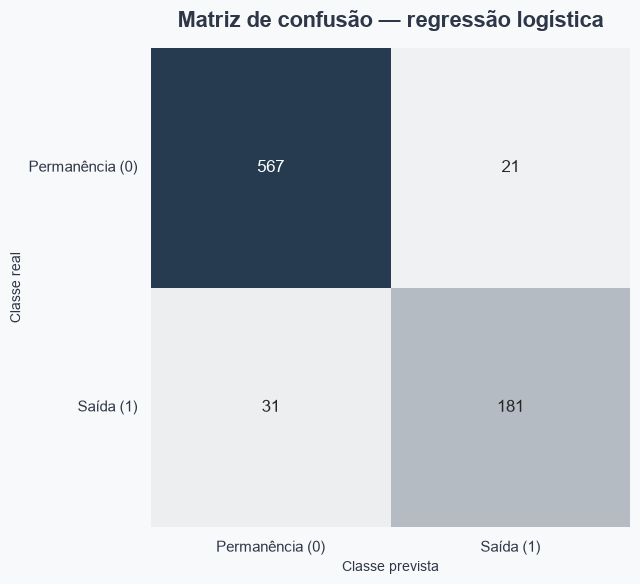

Permaneceram e foram classificados corretamente: 567
Permaneceram, mas receberam alerta de saída: 21
Saíram, mas não foram identificados: 31
Saíram e foram identificados corretamente: 181


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix

# Criar uma referência que prevê a classe mais frequente no treino
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_valid)

# Comparar a referência com a regressão logística
baseline_comparison = pd.DataFrame({
    'Modelo': ['Sempre prever permanência', 'Regressão logística'],
    'Acurácia': [
        accuracy_score(y_valid, baseline_predictions),
        accuracy_score(y_valid, logistic_predictions)
    ],
    'Precisão': [
        precision_score(y_valid, baseline_predictions, zero_division=0),
        precision_score(y_valid, logistic_predictions, zero_division=0)
    ],
    'Sensibilidade': [
        recall_score(y_valid, baseline_predictions),
        recall_score(y_valid, logistic_predictions)
    ]
}).set_index('Modelo')

display(formatar_tabela(baseline_comparison, casas=3))

# Calcular os acertos e erros da regressão logística
confusion = confusion_matrix(
    y_valid, logistic_predictions, labels=[0, 1]
)
true_negative, false_positive, false_negative, true_positive = (
    confusion.ravel()
)

# Visualizar a matriz com a paleta centralizada
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt='d',
    annot_kws={'size': 12},
    cmap=sns.light_palette(CORES['azul_escuro'], as_cmap=True),
    cbar=False,
    square=True,
    xticklabels=['Permanência (0)', 'Saída (1)'],
    yticklabels=['Permanência (0)', 'Saída (1)'],
    ax=ax
)

ax.set_title('Matriz de confusão — regressão logística', pad=15)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

# Apresentar os resultados em quantidade de clientes
print(f'Permaneceram e foram classificados corretamente: {true_negative}')
print(f'Permaneceram, mas receberam alerta de saída: {false_positive}')
print(f'Saíram, mas não foram identificados: {false_negative}')
print(f'Saíram e foram identificados corretamente: {true_positive}')

A referência de prever permanência para todos alcança 73,5% de acurácia, mas não identifica nenhum cliente que saiu. A regressão logística aumenta a acurácia para 93,5%, um ganho de 20 pontos percentuais, e identifica 181 dos 212 clientes que saíram.

Dos 202 alertas de saída, 181 estão corretos e 21 correspondem a clientes que permaneceram. Outros 31 clientes saíram sem receber alerta, mostrando que o modelo não substitui o acompanhamento da frequência e do relacionamento.

Na prática, o modelo permite direcionar uma ação de contato a 202 dos 800 clientes da validação, alcançando 85,4% das saídas observadas. Isso demonstra potencial para priorização, mas não significa que essas saídas seriam evitadas: o efeito da intervenção precisa ser testado.

### Avaliação complementar das probabilidades previstas

A classificação anterior utiliza o limiar padrão de 0,5. Esta avaliação complementa a comparação usando as probabilidades de saída já produzidas pelos dois modelos, na mesma amostra de validação.

Serão apresentados:

- **ROC-AUC:** avalia a capacidade de ordenar clientes que saíram acima daqueles que permaneceram, considerando diferentes limiares.
- **Precisão média (Average Precision):** resume a curva de precisão–sensibilidade, com foco na classe de saída.
- **Curva de precisão–sensibilidade:** mostra a relação entre identificar mais clientes que saem e manter a precisão dos alertas.

A proporção de clientes que saíram na validação será apresentada como referência para a curva de precisão–sensibilidade.

Essas medidas avaliam a ordenação dos riscos, mas não comprovam que as probabilidades estejam calibradas. A análise não altera o limiar de classificação nem substitui a validação em períodos futuros.

,ROC-AUC,Precisão média (AP)
Modelo,,
Regressão logística,"0,978","0,950"
Floresta aleatória,"0,970","0,930"


Proporção de saídas na validação: 26,50%


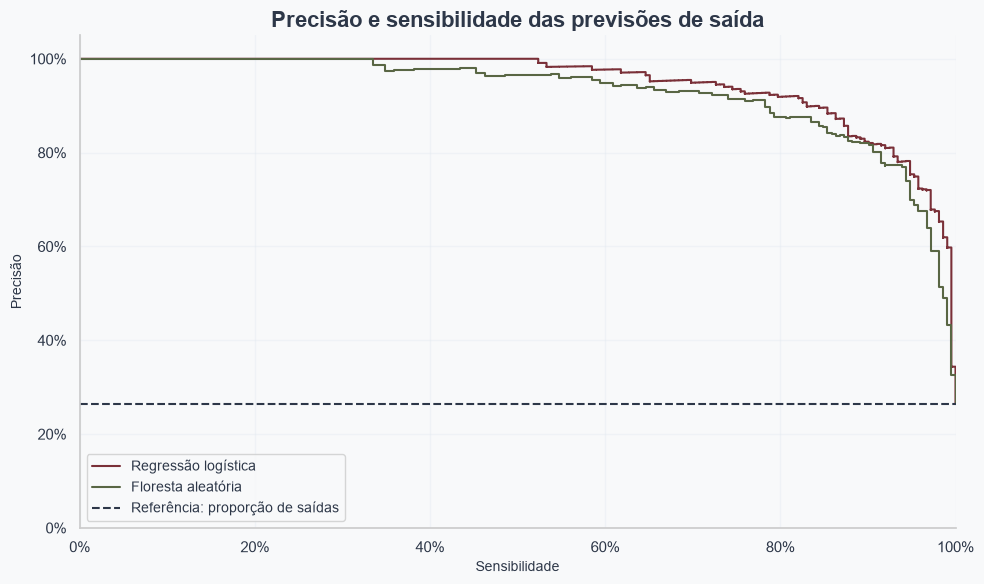

In [9]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Usar as probabilidades já calculadas
probabilidades_modelos = {
    'Regressão logística': logistic_probabilities,
    'Floresta aleatória': forest_probabilities
}

metricas_probabilidades = pd.DataFrame([
    {
        'Modelo': nome,
        'ROC-AUC': roc_auc_score(y_valid, probabilidades),
        'Precisão média (AP)': average_precision_score(
            y_valid, probabilidades
        )
    }
    for nome, probabilidades in probabilidades_modelos.items()
]).set_index('Modelo')

display(formatar_tabela(metricas_probabilidades, casas=3))

# Referência para a curva de precisão–sensibilidade
proporcao_saidas_validacao = y_valid.mean()

print(
    'Proporção de saídas na validação: '
    + f'{proporcao_saidas_validacao:.2%}'.replace('.', ',')
)

# Comparar os modelos usando as cores centralizadas
fig, ax = plt.subplots(figsize=(10, 6))

for nome, probabilidades in probabilidades_modelos.items():
    precisao, sensibilidade, _ = precision_recall_curve(
        y_valid, probabilidades
    )

    ax.step(
        sensibilidade,
        precisao,
        where='post',
        color=cores_modelos[nome],
        label=nome
    )

ax.axhline(
    proporcao_saidas_validacao,
    color=CORES['texto'],
    linestyle='--',
    label='Referência: proporção de saídas'
)

ax.set_title('Precisão e sensibilidade das previsões de saída')
ax.set_xlabel('Sensibilidade')
ax.set_ylabel('Precisão')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend()
ax.grid(alpha=0.4)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Resultados — avaliação das probabilidades**

Na validação, a regressão logística apresentou ROC-AUC de 0,978 e precisão média (AP) de aproximadamente 0,95. A floresta aleatória alcançou 0,970 e aproximadamente 0,93, respectivamente.

A regressão logística obteve valores maiores nas duas métricas, complementando seu melhor desempenho na classificação com limiar de 0,5. Essas diferenças são descritivas nesta amostra; não foi realizado um teste de significância entre os modelos.

A proporção de saídas na validação foi de 26,50%, utilizada como referência para a curva de precisão–sensibilidade. Os dois modelos apresentaram precisão média superior a essa referência.

A curva permite examinar como a precisão varia ao ampliar a identificação de clientes que saem. A escolha de um limiar operacional dependerá dos custos dos erros e da capacidade de contato da equipe; nenhum novo limiar foi selecionado nesta análise.

Esses resultados avaliam a ordenação dos riscos, sem comprovar a calibração das probabilidades ou garantir desempenho semelhante em meses futuros.

### 3.4. Escolhas metodológicas e limitações

Foram mantidas as 13 características para a comparação inicial dos modelos. A regressão logística utiliza regularização L2 por padrão, que penaliza coeficientes elevados e ajuda a lidar com características correlacionadas. Ainda assim, seus coeficientes não devem ser interpretados isoladamente como efeitos causais.

Foi mantido o limiar padrão de 0,5 para a classificação. Sua alteração pode aumentar a identificação de clientes que saem, mas também gerar mais alertas incorretos. Uma escolha operacional exige conhecer a capacidade de atendimento e os custos dessas decisões.

Os resultados foram obtidos em uma única divisão aleatória e estratificada de treino e validação. Como a base não apresenta datas individuais para uma separação temporal, o desempenho em meses futuros ainda precisa ser verificado.

Antes do uso operacional, também será necessário confirmar que todas as características, especialmente a frequência do mês corrente, estão disponíveis no momento da previsão e se referem a um período anterior à saída que se deseja prever.

## 4. Agrupamento de clientes

Os clientes serão agrupados por semelhança de suas características, sem utilizar `Churn` na formação dos grupos. Depois, as taxas de rotatividade serão comparadas para identificar perfis com maior e menor ocorrência de saída.

### 4.1. Padronização das características

As 13 características serão padronizadas para que suas diferentes escalas não dominem o cálculo das distâncias. A variável `Churn` ficará fora dessa transformação e será utilizada posteriormente para comparar a rotatividade dos grupos.

Como o objetivo é segmentar os 4.000 clientes da base, a padronização será ajustada sobre todas as observações, separadamente daquela utilizada na classificação.

In [10]:
# Separar as características, excluindo a variável alvo
cluster_features = gym.drop('Churn', axis=1)

# Padronizar as características para o agrupamento
cluster_scaler = StandardScaler()
cluster_features_scaled = cluster_scaler.fit_transform(cluster_features)

# Conferir as dimensões da matriz padronizada
print(f'Clientes: {cluster_features_scaled.shape[0]}')
print(f'Características: {cluster_features_scaled.shape[1]}')

# Exibir os primeiros cinco registros com o padrão definido
amostra_padronizada = pd.DataFrame(
    cluster_features_scaled,
    columns=cluster_features.columns,
    index=cluster_features.index
).head()

display(formatar_tabela(amostra_padronizada))

Clientes: 4000
Características: 13


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month
0,"0,98","0,43","1,03","1,50","-3,06","0,29","1,19","-0,06","-1,38","0,16","-0,19","-1,91","-1,68"
1,"-1,02","0,43","-0,97","-0,67","0,33","1,61","1,19","0,56","-0,35","1,83","0,87","0,05","0,14"
2,"-1,02","0,43","1,03","-0,67","0,33","-0,81","-0,84","-0,36","-0,18","-0,79","-0,46","-0,02","-0,03"
3,"-1,02","0,43","1,03","1,50","0,33","1,61","1,19","1,17","-0,87","1,83","-0,46","1,36","1,51"
4,"0,98","0,43","1,03","1,50","0,33","-0,81","-0,84","-0,98","0,53","-0,79","-0,19","-0,79","-0,61"


### 4.2. Agrupamento hierárquico e dendrograma

Será utilizada a função `linkage()` com o método Ward para construir o agrupamento hierárquico a partir das características padronizadas.

O dendrograma permitirá observar as uniões entre grupos e estimar visualmente uma quantidade de agrupamentos. Depois, o K-means será aplicado com cinco grupos, conforme solicitado no enunciado.

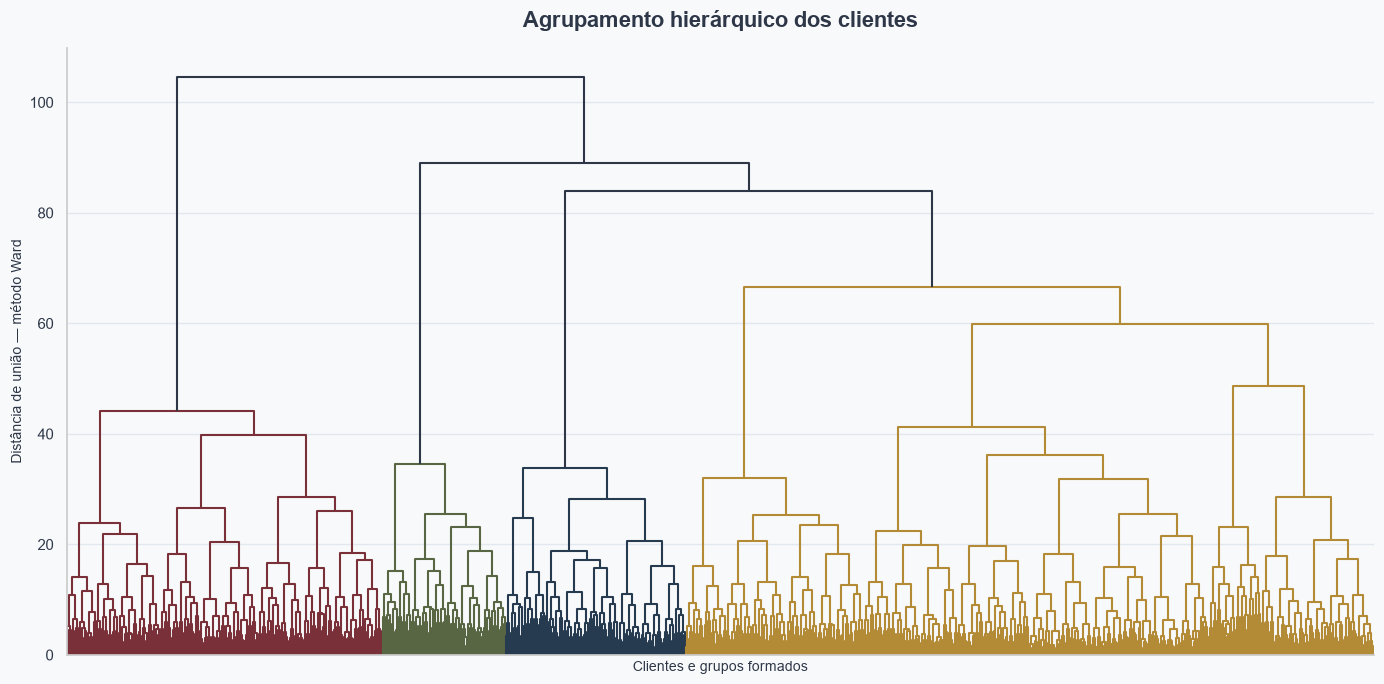

In [11]:
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    set_link_color_palette
)

# Construir o agrupamento hierárquico com o método Ward
linked = linkage(cluster_features_scaled, method='ward')

# Reutilizar a paleta centralizada
set_link_color_palette(list(cluster_colors.values()))

fig, ax = plt.subplots(figsize=(14, 7))

try:
    dendrogram(
        linked,
        no_labels=True,
        above_threshold_color=CORES['texto'],
        ax=ax
    )
finally:
    set_link_color_palette(None)

ax.set_title('Agrupamento hierárquico dos clientes', pad=15)
ax.set_xlabel('Clientes e grupos formados')
ax.set_ylabel('Distância de união — método Ward')

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

O dendrograma apresenta quatro grupos principais no corte automático de cores. Um corte entre aproximadamente 60 e 65 na distância de união permite distinguir cinco grupos, dividindo o maior ramo à direita.

Essa leitura oferece uma referência exploratória, sem determinar uma quantidade única ideal. Na próxima etapa, serão utilizados cinco agrupamentos no K-means, conforme solicitado no enunciado.

### 4.3. Formação dos grupos com K-means

O K-means será aplicado às características padronizadas para formar cinco grupos, conforme o enunciado, utilizando `random_state=0`.

Cada cliente receberá um identificador de grupo de 0 a 4. Esses números são apenas rótulos, sem ordem de risco ou importância. As médias das características na escala original serão utilizadas para interpretar os perfis.

In [12]:
from sklearn.cluster import KMeans

# Formar cinco grupos com as características padronizadas
kmeans_model = KMeans(n_clusters=5, random_state=0, n_init=10)
cluster_labels = kmeans_model.fit_predict(cluster_features_scaled)

# Armazenar os grupos em uma cópia da base original
gym_clusters = gym.copy()
gym_clusters['cluster'] = cluster_labels

# Conferir a quantidade de clientes por grupo
quantidade_por_grupo = (
    gym_clusters['cluster']
    .value_counts()
    .sort_index()
    .rename_axis('Grupo')
    .to_frame('Clientes')
)

display(formatar_tabela(quantidade_por_grupo))

# Comparar as médias das características na escala original
cluster_profile = gym_clusters.groupby('cluster')[
    cluster_features.columns
].mean().T

display(formatar_tabela(cluster_profile))

,Clientes
Grupo,
0,545
1,768
2,642
3,937
4,1108


cluster,0,1,2,3,4
gender,"0,50","0,59","0,48","0,50","0,49"
Near_Location,"0,00","0,97","1,00","0,95","1,00"
Partner,"0,47","0,26","0,82","0,74","0,24"
Promo_friends,"0,08","0,09","1,00","0,49","0,02"
Phone,"0,92","0,90","0,90","0,90","0,90"
Contract_period,"2,23","2,81","3,16","11,87","1,99"
Group_visits,"0,21","0,48","0,45","0,55","0,32"
Age,"28,48","30,14","29,22","29,93","28,21"
Avg_additional_charges_total,"133,86","162,01","141,20","164,76","131,19"
Month_to_end_contract,"2,09","2,59","2,92","10,87","1,90"


Os cinco grupos apresentam os seguintes perfis médios:

- **Grupo 0:** clientes que não moram nem trabalham próximo à academia, com contratos relativamente curtos e baixa participação em atividades coletivas.
- **Grupo 1:** clientes com maior frequência de visitas, próxima de 2,88 vezes por semana, e maior tempo médio de relacionamento com a academia.
- **Grupo 2:** clientes que aderiram por indicação de amigos. Cerca de 82% possuem vínculo com empresas parceiras.
- **Grupo 3:** clientes com contratos mais longos, próximos de 12 meses em média, maior gasto médio com serviços adicionais e elevada participação de vínculos com empresas parceiras.
- **Grupo 4:** clientes com contratos curtos, menor tempo médio de relacionamento e baixa frequência de visitas. A frequência média no mês corrente é inferior à média histórica do grupo.

Essas características descrevem médias e não representam necessariamente cada integrante dos grupos. A variável `Churn` foi excluída da formação dos agrupamentos e será utilizada posteriormente para comparar suas taxas de saída.

Os números dos grupos são identificadores do algoritmo e não indicam uma ordem de risco.

### 4.4. Distribuição das características por grupo

Serão comparadas as distribuições das características nos cinco grupos, complementando a análise das médias. As proporções serão calculadas separadamente em cada grupo para permitir a comparação entre segmentos de tamanhos diferentes.

Cada grupo manterá a mesma cor em todos os gráficos.

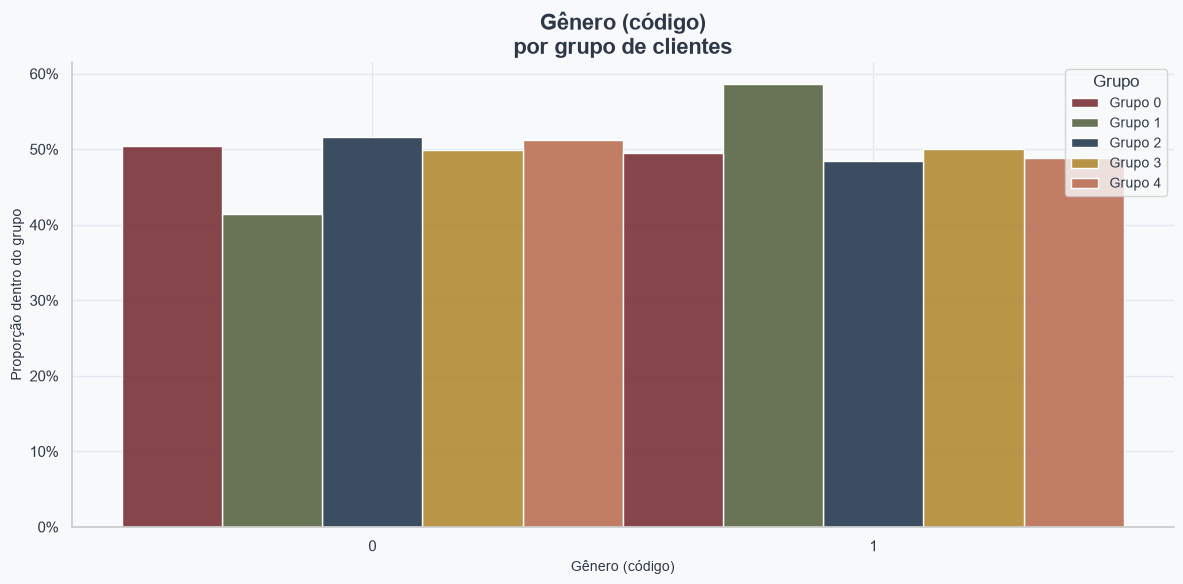

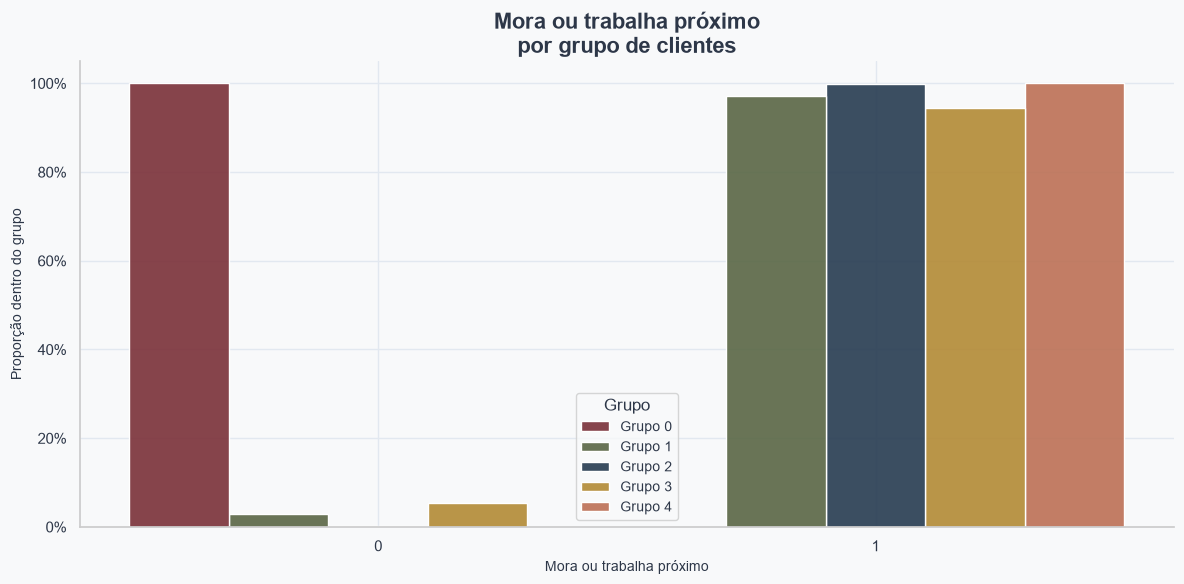

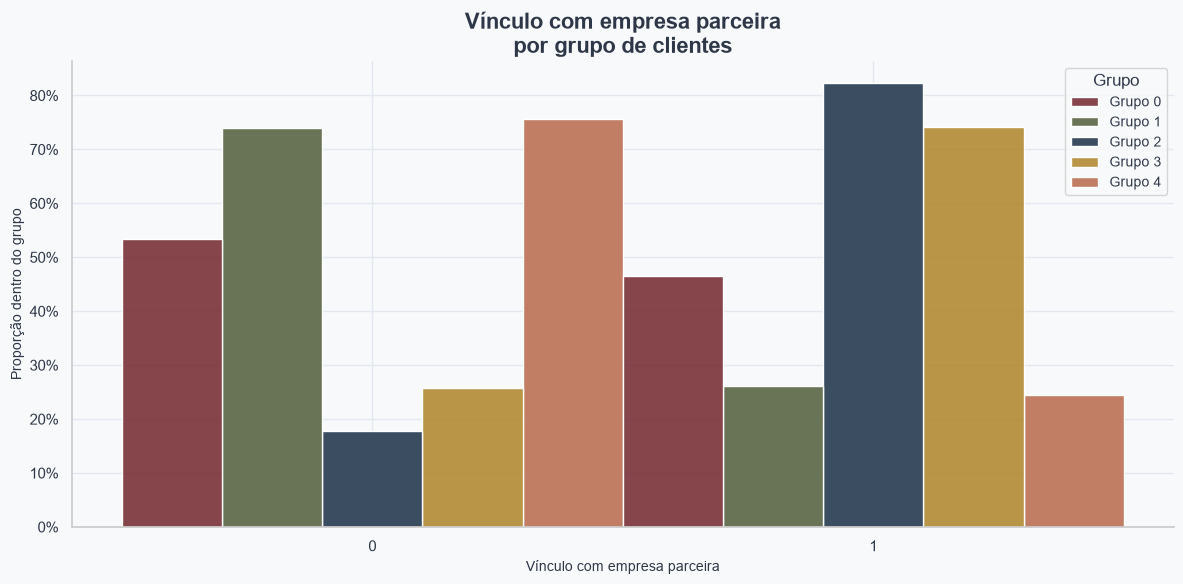

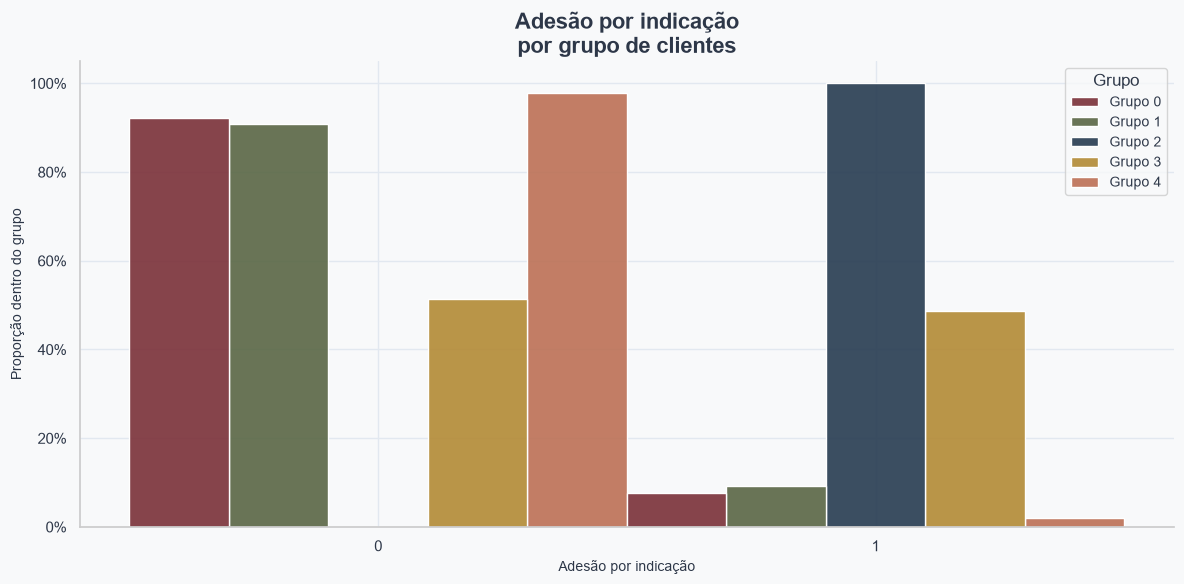

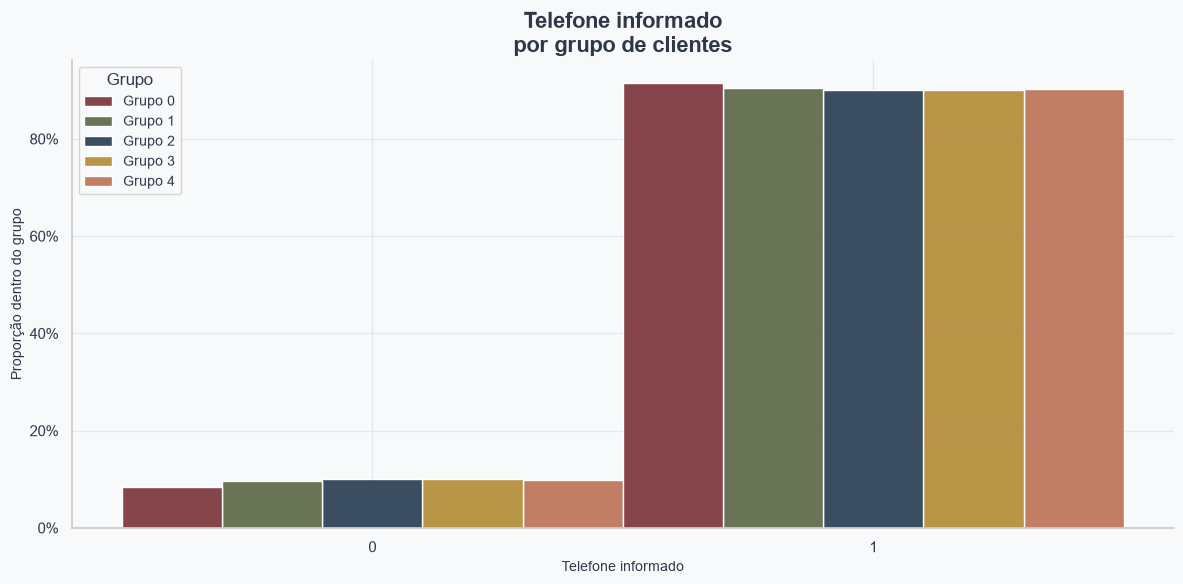

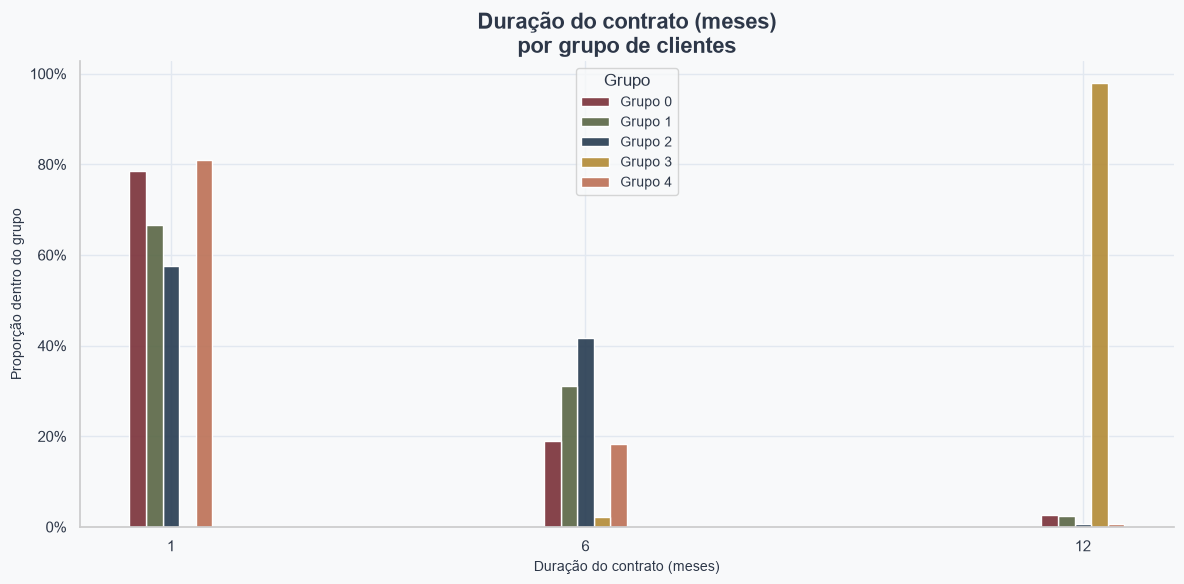

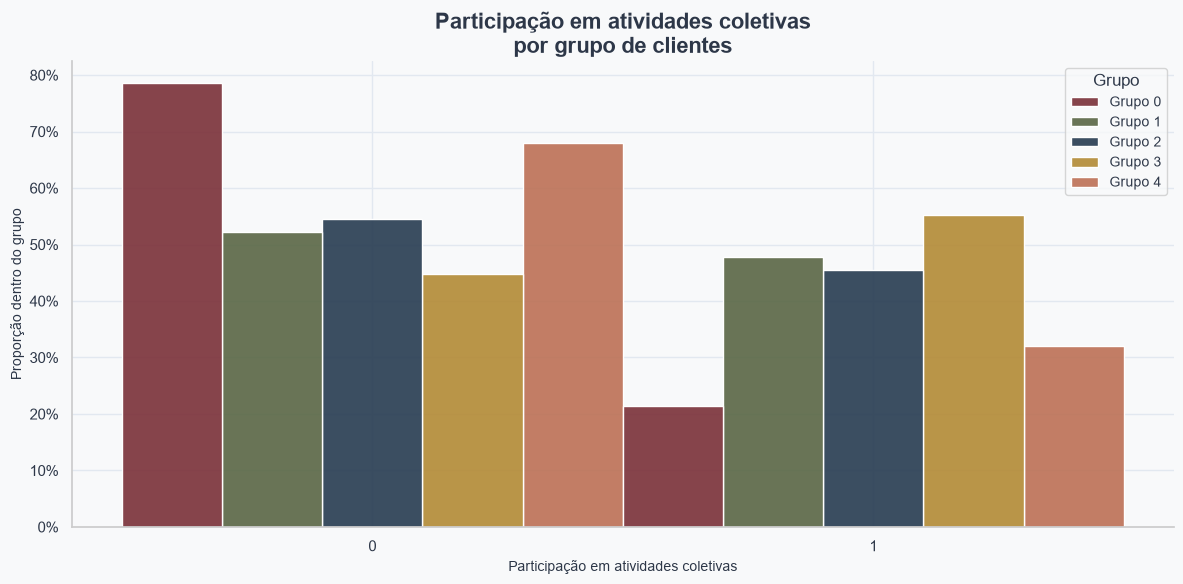

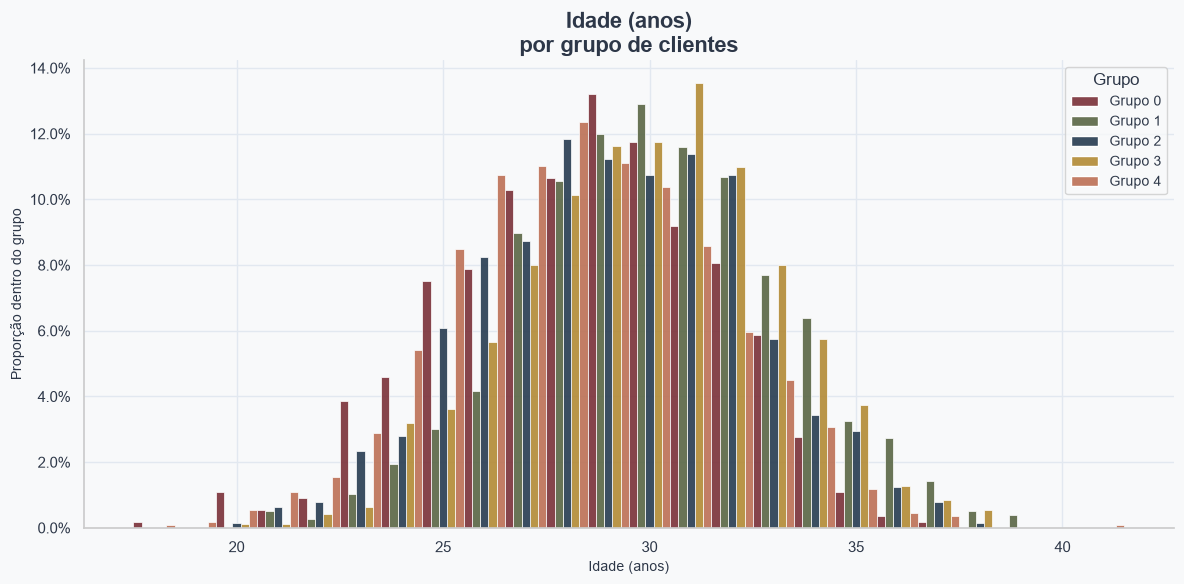

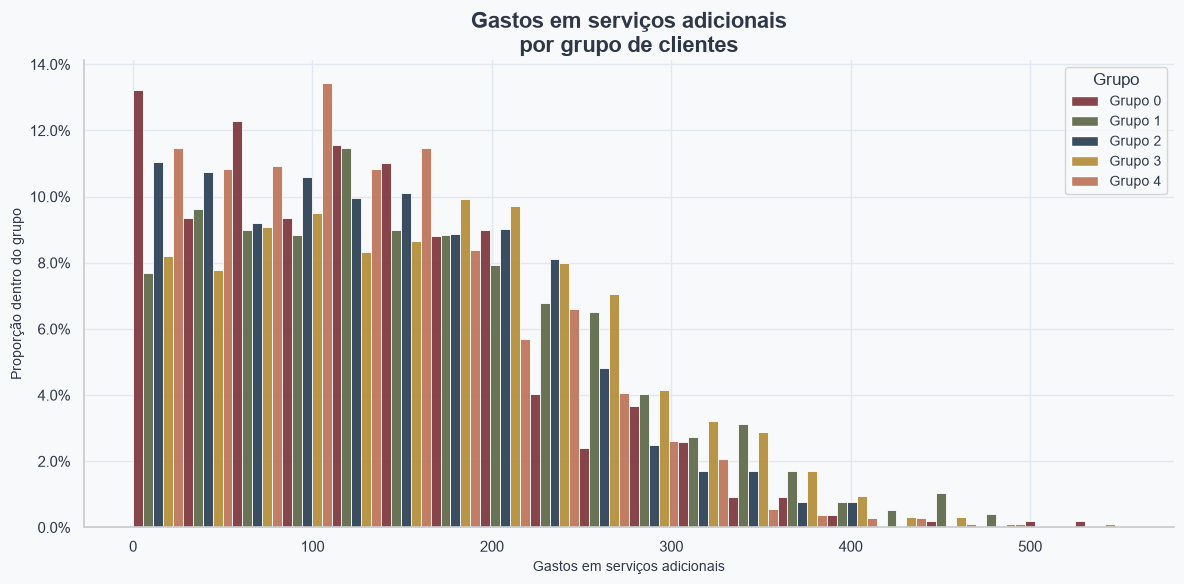

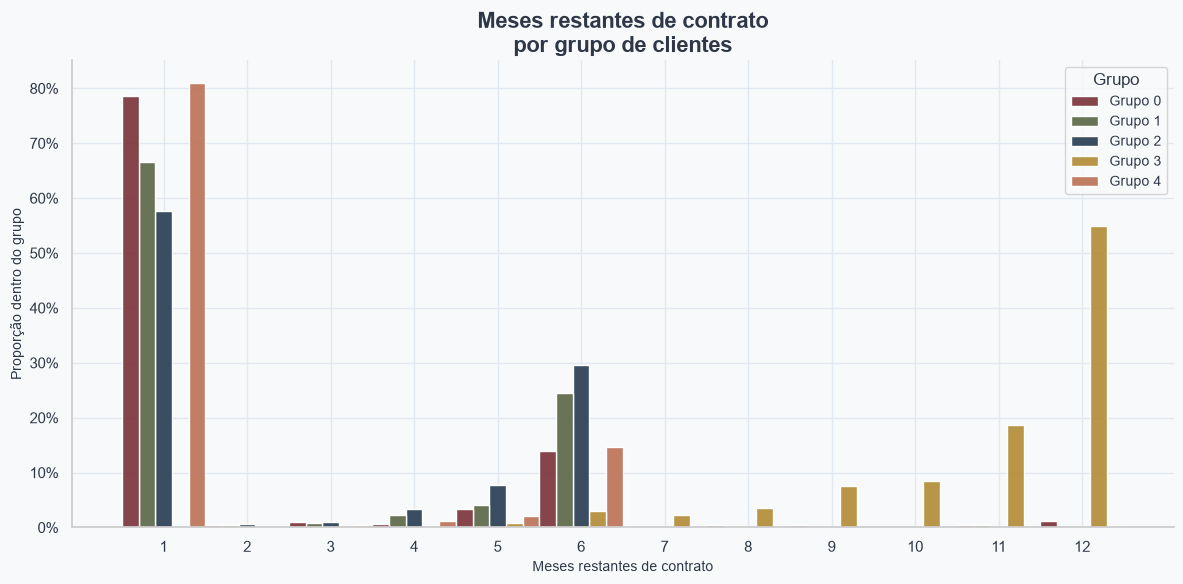

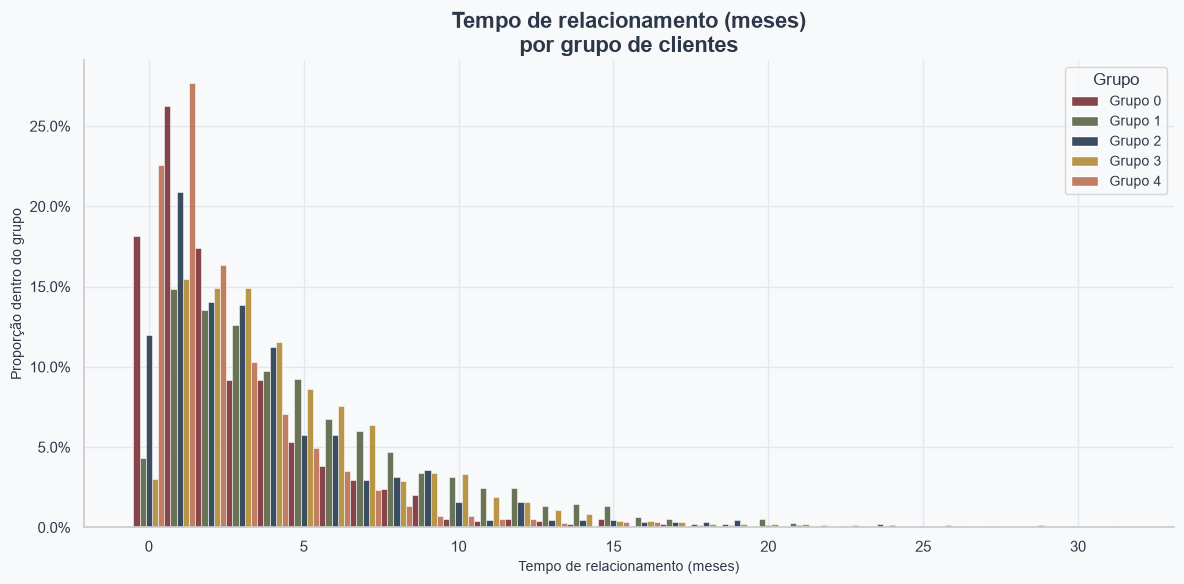

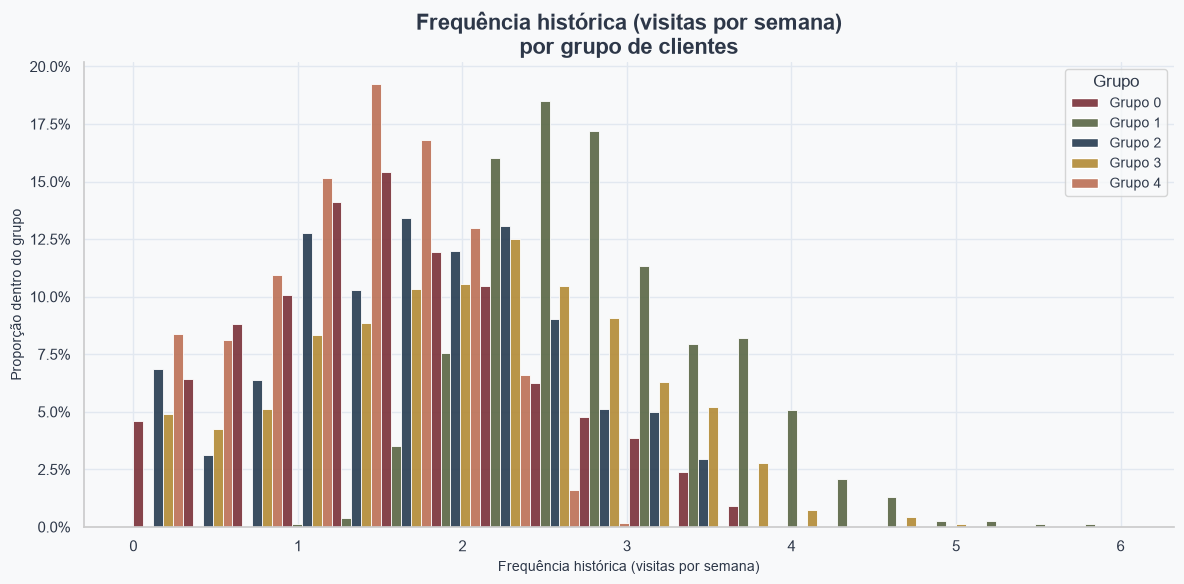

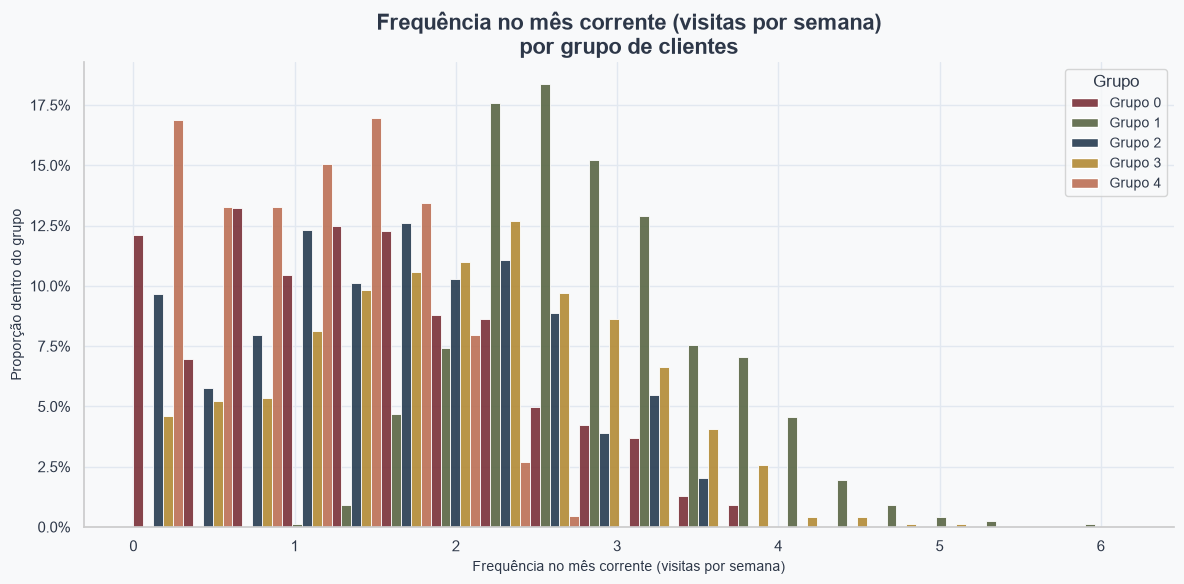

In [13]:
# Criar rótulos para os gráficos sem alterar os grupos originais
cluster_plot_data = gym_clusters.copy()
cluster_plot_data['Grupo'] = cluster_plot_data['cluster'].map({
    i: f'Grupo {i}' for i in range(5)
})

# Comparar as distribuições das características entre os grupos
for feature, label in feature_labels.items():
    fig, ax = plt.subplots(figsize=(12, 6))

    hist_options = {'bins': 20}
    if feature in discrete_features:
        hist_options = {'discrete': True}

    sns.histplot(
        data=cluster_plot_data,
        x=feature,
        hue='Grupo',
        hue_order=cluster_order,
        palette=cluster_colors,
        stat='probability',
        common_norm=False,
        common_bins=True,
        multiple='dodge',
        alpha=0.9,
        ax=ax,
        **hist_options
    )

    ax.set_title(f'{label}\npor grupo de clientes')
    ax.set_xlabel(label)
    ax.set_ylabel('Proporção dentro do grupo')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    if feature in discrete_features:
        values = sorted(gym_clusters[feature].unique())
        if len(values) <= 12:
            ax.set_xticks(values)

    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

As distribuições complementam os perfis identificados nas médias. O grupo 3 concentra contratos anuais, enquanto o grupo 4 apresenta maior concentração em contratos mensais e frequências baixas. O grupo 1 se destaca pela frequência elevada, tanto histórica quanto no mês corrente.

A localização distingue o grupo 0, formado por clientes que não moram nem trabalham próximo à academia. O grupo 2 reúne clientes que aderiram por indicação de amigos. O fornecimento de telefone não caracteriza um grupo exclusivo nesta execução.

As distribuições de gênero são semelhantes entre os grupos, enquanto idade e gastos adicionais apresentam sobreposição.

A segmentação combina características de cadastro, contrato e comportamento. A comparação das taxas de rotatividade permitirá identificar quais desses perfis apresentam maior ocorrência de saída.

### 4.5. Rotatividade por grupo

Será calculada a proporção de clientes que saíram em cada agrupamento, usando a média de `Churn`. As taxas serão comparadas com a rotatividade geral da base para identificar os segmentos com maior e menor ocorrência de saída.

Essa comparação ajudará a definir prioridades para as ações de retenção.

,clientes,saidas,taxa_churn
cluster,,,
0,545,245,"44,95%"
1,768,53,"6,90%"
2,642,159,"24,77%"
3,937,21,"2,24%"
4,1108,583,"52,62%"


Rotatividade geral: 26,52%


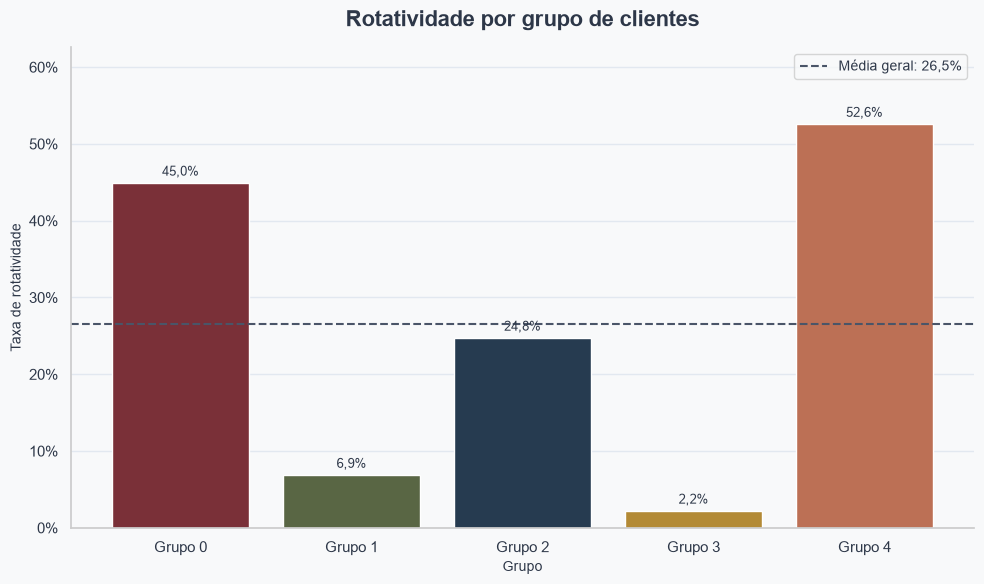

In [14]:
# Calcular a quantidade de clientes e a rotatividade por grupo
cluster_churn = gym_clusters.groupby('cluster')['Churn'].agg(
    clientes='count',
    saidas='sum',
    taxa_churn='mean'
)

display(
    formatar_tabela(
        cluster_churn,
        formatos={
            'taxa_churn': lambda valor: (
                f'{valor:.2%}'.replace('.', ',')
            )
        }
    )
)

# Calcular a taxa geral para comparação
overall_churn = gym['Churn'].mean()

print(
    'Rotatividade geral: '
    + f'{overall_churn:.2%}'.replace('.', ',')
)

# Comparar as taxas usando as cores centralizadas
fig, ax = plt.subplots(figsize=(10, 6))

group_names = [f'Grupo {i}' for i in cluster_churn.index]

bars = ax.bar(
    group_names,
    cluster_churn['taxa_churn'],
    color=[cluster_colors[nome] for nome in group_names]
)

ax.axhline(
    overall_churn,
    color=CORES['referencia'],
    linestyle='--',
    label=(
        'Média geral: '
        + f'{overall_churn:.1%}'.replace('.', ',')
    )
)

# Exibir os percentuais sobre as barras
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f'{height:.1%}'.replace('.', ','),
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

ax.set_title('Rotatividade por grupo de clientes', pad=15)
ax.set_xlabel('Grupo')
ax.set_ylabel('Taxa de rotatividade')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylim(0, min(1, cluster_churn['taxa_churn'].max() + 0.1))
ax.legend()
ax.grid(axis='x', visible=False)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

O grupo 4 apresenta a maior taxa de rotatividade: 52,62%. Seus 583 clientes que saíram representam aproximadamente 55% das 1.061 saídas da base. Esse grupo combina contratos curtos, menor tempo de relacionamento e baixa frequência de visitas.

O grupo 0 também apresenta rotatividade elevada, de 44,95%. A ausência de proximidade com a academia caracteriza esse perfil, mas a análise não permite afirmar que a localização seja a causa das saídas.

Os grupos 1 e 3 apresentam as menores taxas de rotatividade, de 6,90% e 2,24%, respectivamente. O grupo 1 se destaca pela frequência elevada, enquanto o grupo 3 concentra contratos longos.

O grupo 2 apresenta rotatividade de 24,77%, próxima da taxa geral de 26,52%, e reúne clientes que aderiram por indicação de amigos.

Os grupos 4 e 0 são prioritários para investigar dificuldades de permanência e testar ações de retenção. Essas diferenças são descritivas: não demonstram causalidade nem garantem a eficácia de uma intervenção.

### 4.6. Síntese dos segmentos

| Grupo | Clientes | Perfil predominante | Rotatividade |
|---|---:|---|---:|
| 0 | 545 | Sem proximidade com a academia, contratos curtos e baixa participação em atividades coletivas | 44,95% |
| 1 | 768 | Frequência elevada e maior tempo médio de relacionamento | 6,90% |
| 2 | 642 | Adesão por indicação e elevada participação de vínculos com empresas parceiras | 24,77% |
| 3 | 937 | Contratos longos, maior gasto médio adicional e elevada participação de vínculos com empresas parceiras | 2,24% |
| 4 | 1.108 | Contratos curtos, menor tempo de relacionamento e baixa frequência | 52,62% |

Os grupos 4 e 0 apresentam as maiores taxas de saída e merecem prioridade na investigação de dificuldades de permanência. Os grupos 1 e 3 oferecem referências de perfis associados à retenção, sem demonstrar que suas características sejam causas da permanência.

A segmentação descreve padrões da base analisada. Sua aplicação a novos clientes exige preservar a preparação dos dados e o modelo ajustado, além de acompanhar a estabilidade dos perfis ao longo do tempo.

## 5. Conclusões e recomendações

A análise identificou perfis associados à rotatividade e um modelo capaz de apoiar a priorização de contatos. As recomendações a seguir combinam esses resultados com ações práticas de retenção, cuja eficácia deverá ser testada e acompanhada.

### 5.1. Principais conclusões

- A rotatividade geral foi de **26,52%**. As saídas estão associadas a menor tempo de relacionamento, contratos curtos e baixa frequência, especialmente no mês corrente.

- A **regressão logística** superou a floresta aleatória nas três métricas avaliadas no limiar de 0,5, alcançando **93,5% de acurácia, 89,6% de precisão e 85,4% de sensibilidade**.

- Na avaliação das probabilidades, a regressão logística apresentou **ROC-AUC de 0,978 e precisão média (AP) de aproximadamente 0,95**, frente a **0,970 e 0,93** da floresta aleatória. Esses resultados complementam a comparação no limiar de 0,5, mas não comprovam calibração das probabilidades nem desempenho futuro.

- Na validação, a regressão logística identificou **181 dos 212 clientes que saíram**, com **21 alertas incorretos e 31 saídas não identificadas**. A referência de prever permanência para todos obteve 73,5% de acurácia, mas não identificou nenhuma saída.

- Os **grupos 4 e 0** são prioritários para investigar dificuldades de permanência e testar ações de retenção, com rotatividade de **52,62% e 44,95%**, respectivamente. O grupo 4 concentra aproximadamente **55% das saídas** da base.

- Os **grupos 3 e 1** apresentam as menores taxas de rotatividade, de **2,24% e 6,90%**, respectivamente. O grupo 3 se caracteriza por contratos longos, enquanto o grupo 1 se destaca pela frequência elevada.

O modelo ajuda a priorizar quem contatar, enquanto os segmentos orientam a abordagem. Os resultados não comprovam causas da saída nem garantem o efeito das ações propostas. A aplicação requer validação em períodos futuros e avaliação das intervenções.

### 5.2. Recomendações para retenção

As ações abaixo são propostas para testes, fundamentadas nos perfis observados. Os gatilhos operacionais são sugestões iniciais, não limites comprovados pela análise.

| Público prioritário | Gatilho proposto | Ação ou oferta a testar | Canal |
|---|---|---|---|
| Clientes novos com baixa frequência, perfil observado no grupo 4 | Primeiras semanas de relacionamento e ausência de visitas por sete dias | Contato de acolhimento, orientação de treino e convite para uma atividade coletiva compatível com seus interesses | Canal autorizado e preferido pelo cliente; abordagem presencial quando houver visita |
| Clientes com redução de frequência | Queda de visitas em relação ao próprio histórico | Conversa para identificar dificuldades e apoio para reorganizar horários e rotina | Canal autorizado disponível no cadastro |
| Clientes com contrato mensal próximo do vencimento | Renovação prevista para os próximos 30 dias | Apresentar opções de planos mais longos e testar um benefício de renovação, condicionado à viabilidade financeira | Atendimento presencial ou canal autorizado |
| Clientes que não moram nem trabalham próximos, perfil do grupo 0 | Dificuldade de acesso relatada ou redução de frequência | Investigar deslocamento e testar sugestões de horários ou unidades mais convenientes, quando disponíveis | Pesquisa breve ou contato individual |
| Clientes vinculados a empresas parceiras | Renovação de contrato ou campanha acordada com a empresa | Testar comunicação dos benefícios da parceria e convite para atividades coletivas | Canal da parceria, respeitando as autorizações de contato |
| Clientes com participação regular, incluindo perfis dos grupos 1 e 3 | Interesse em convidar alguém | Testar campanha de indicação com benefício previamente definido e economicamente viável | Convite presencial ou canal autorizado |

Os grupos são segmentos descritivos, não regras automáticas de elegibilidade. Na comparação geral entre clientes que saíram e permaneceram, parcerias, indicações e contratos longos apresentaram associação com a permanência. Isso não comprova que ampliar essas condições causará maior retenção, nem que todos os segmentos com essas características tenham o mesmo risco de saída.

A ausência de telefone não deve excluir o cliente das ações nem ser interpretada isoladamente como risco. Deve-se confirmar outro canal autorizado de contato, quando disponível.

As probabilidades do modelo podem apoiar a priorização, após confirmar a disponibilidade das características no momento da previsão. ROC-AUC e precisão média não garantem que os valores previstos representem probabilidades calibradas.

#### Avaliação das iniciativas

Cada ação deve começar com um teste de escopo definido, com atribuição aleatória entre intervenção e comparação, quando viável. Acompanhar:

- Rotatividade no mês seguinte como resultado principal.
- Frequência de visitas e adesão à oferta como indicadores complementares.
- Custo da ação e dos benefícios concedidos.
- Reclamações e pedidos para interromper contatos.

A quantidade incremental de clientes retidos deve ser estimada pela comparação entre os grupos, considerando a incerteza dos resultados. O custo por cliente adicional retido só será interpretável quando houver evidência de ganho positivo.

As iniciativas serão ampliadas conforme os resultados dos testes e a viabilidade operacional, sem presumir eficácia a partir das associações observadas.